# make some plots using the computed healthscore and the training data
### The healthscore can be found in the experiment folder for whichever run created the score, while the training data will be saved as a dataframe in the "experiments" directory and will have a name generated by combining the name of the original file and the proportion of encounters with data (which is used to decide which features to use)

In [96]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [97]:
training_data_filename = "combined_hourly_features_phoenix_sepsis_prop_0.8.parquet"

experiments_dir = "/home/jake/Documents/AI_Clinician/experiments"
training_data_path = Path(experiments_dir) / training_data_filename

print(f"Loading training data from {training_data_path}")

training_data = pd.read_parquet(training_data_path)
training_data.head()

Loading training data from /home/jake/Documents/AI_Clinician/experiments/combined_hourly_features_phoenix_sepsis_prop_0.8.parquet


,MASKED_ENCNTR_ID,EVENT_END_DT_TM,airway_type,breath_sequence,control_variable,expiratory_pressure,fio2,mean_airway_pressure,mode_of_ventilation,nitric_oxide,...,temperature,vis,age,mortality,sex,white,black,hispanic,asian,other
0,1165293630,2239-06-12 00:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.400000,0.0,0.0,0.0,1.0,0,0,0,1,0
1,1165293630,2239-06-12 01:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.433333,0.0,0.0,0.0,1.0,0,0,0,1,0
2,1165293630,2239-06-12 02:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.466667,0.0,0.0,0.0,1.0,0,0,0,1,0
3,1165293630,2239-06-12 03:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.500000,0.0,0.0,0.0,1.0,0,0,0,1,0
4,1165293630,2239-06-12 04:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.450000,0.0,0.0,0.0,1.0,0,0,0,1,0


In [98]:
experiment_type = "xgbclassifier_discharge_mortality_choc_grid_search"
date_time = "20250814_185430"

file_name = "all_predictions.parquet"
file_path = Path(experiments_dir) / experiment_type / date_time / file_name

print(f"Loading predictions from {file_path}")

predictions_df = pd.read_parquet(file_path)
predictions_df.head()

Loading predictions from /home/jake/Documents/AI_Clinician/experiments/xgbclassifier_discharge_mortality_choc_grid_search/20250814_185430/all_predictions.parquet


,encounter_id,time,true_label,predicted_label,predicted_proba,predicted_proba_class_0,predicted_proba_class_1,predicted_proba_class_2,health_score
0,1165293630,2239-06-12 00:00:00,1.0,1,0.920882,0.021796,0.920882,0.057322,1.035526
1,1165293630,2239-06-12 01:00:00,1.0,1,0.922010,0.021912,0.922010,0.056078,1.034166
2,1165293630,2239-06-12 02:00:00,1.0,1,0.913959,0.024109,0.913959,0.061932,1.037823
3,1165293630,2239-06-12 03:00:00,1.0,1,0.914117,0.023559,0.914117,0.062324,1.038765
4,1165293630,2239-06-12 04:00:00,1.0,1,0.920695,0.021076,0.920695,0.058229,1.037153


In [99]:
# confirm they are the same length
print(f"Training data length: {len(training_data)}")
print(f"Predictions data length: {len(predictions_df)}")

if len(training_data) != len(predictions_df):
    raise ValueError("Training data and predictions data have different lengths")

Training data length: 2878190
Predictions data length: 2878190


In [100]:
# create a list of the MASKED_ENCNTR_ID that have non-zero values for vis
vis_encounter_ids = training_data[training_data['vis'] > 0]['MASKED_ENCNTR_ID'].unique().tolist()
print(f"Number of MASKED_ENCNTR_IDs with non-zero VIS: {len(vis_encounter_ids)}")

# create a list of non-survivors
non_survivor_ids = training_data[training_data['mortality'] == 1]['MASKED_ENCNTR_ID'].unique().tolist()
print(f"Number of non-survivor MASKED_ENCNTR_IDs: {len(non_survivor_ids)}")

# make a list of survivors with non-zero VIS
survivor_ids = [enc_id for enc_id in vis_encounter_ids if enc_id not in non_survivor_ids]
print(f"Number of survivor MASKED_ENCNTR_IDs with non-zero VIS: {len(survivor_ids)}")

Number of MASKED_ENCNTR_IDs with non-zero VIS: 1208
Number of non-survivor MASKED_ENCNTR_IDs: 231
Number of survivor MASKED_ENCNTR_IDs with non-zero VIS: 1018


In [101]:
# list the columns in training_data
print("Training data columns:")
print(training_data.columns)

Training data columns:
Index(['MASKED_ENCNTR_ID', 'EVENT_END_DT_TM', 'airway_type', 'breath_sequence',
       'control_variable', 'expiratory_pressure', 'fio2',
       'mean_airway_pressure', 'mode_of_ventilation', 'nitric_oxide',
       'oxygen_flow', 'peep', 'pip', 'weight_kg', 'ecls_support_type',
       'on_ecls', 'cisatracurium', 'furosemide', 'hydralazine', 'labetalol',
       'nitroglycerin', 'nitroprusside', 'intake', 'alt', 'calcium',
       'chloride', 'creatinine', 'crp', 'hematocrit', 'hemoglobin',
       'neutrophil_count', 'neutrophil_percent', 'potassium', 'random_glucose',
       'sodium', 'white_blood_cell_count', 'fixed_pupils',
       'pupil_reaction_left_binary', 'pupil_reaction_right_binary',
       'chloral_hydrate', 'chlorothiazide', 'dexamethasone', 'dobutamine_dose',
       'furosemide_med', 'hydrocortisone', 'methylprednisolone', 'metolazone',
       'prednisolone', 'spironolactone', 'cisatracurium_med', 'clonidine_med',
       'dexmedetomidine_infusion', 'dex

In [102]:
training_features_to_use = [

    'fio2', 'mean_airway_pressure', 'airway_type', 'oxygen_flow', 
    
    'random_glucose', 'calcium', 'potassium', 'crp', 'white_blood_cell_count', 'creatinine', 'neutrophil_percent',
    
    'blood_pressure_systolic', 'blood_pressure_diastolic', 'heart_rate', 'temperature', 'oxygen_saturation', 'respiratory_rate', 

    'vis', 'intake'
]
print(f"{len(training_features_to_use)} features to use:")
print(training_features_to_use)

19 features to use:
['fio2', 'mean_airway_pressure', 'airway_type', 'oxygen_flow', 'random_glucose', 'calcium', 'potassium', 'crp', 'white_blood_cell_count', 'creatinine', 'neutrophil_percent', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'heart_rate', 'temperature', 'oxygen_saturation', 'respiratory_rate', 'vis', 'intake']


In [103]:
# keep only the MASKED_ENCNTR_ID, EVENT_END_DT_TM, and features_to_use columns in training_data
training_data = training_data[["MASKED_ENCNTR_ID", "EVENT_END_DT_TM"] + training_features_to_use]
training_data.head()

,MASKED_ENCNTR_ID,EVENT_END_DT_TM,fio2,mean_airway_pressure,airway_type,oxygen_flow,random_glucose,calcium,potassium,crp,...,creatinine,neutrophil_percent,blood_pressure_systolic,blood_pressure_diastolic,heart_rate,temperature,oxygen_saturation,respiratory_rate,vis,intake
0,1165293630,2239-06-12 00:00:00,0.21,0.0,0.0,0.0,87.0,7.00,2.900000,7.2,...,0.510,8.0,70.000000,38.000000,140.0,37.400000,96.0,46.0,0.0,0.00
1,1165293630,2239-06-12 01:00:00,0.21,0.0,0.0,0.0,87.0,7.00,2.900000,7.2,...,0.510,8.0,71.666667,37.333333,122.0,37.433333,94.0,32.0,0.0,0.00
2,1165293630,2239-06-12 02:00:00,0.21,0.0,0.0,0.0,87.0,7.00,2.900000,7.2,...,0.510,8.0,73.333333,36.666667,140.0,37.466667,89.0,47.0,0.0,25.00
3,1165293630,2239-06-12 03:00:00,0.21,0.0,0.0,0.0,85.2,7.02,3.028571,7.2,...,0.511,8.0,75.000000,36.000000,132.0,37.500000,96.0,55.0,0.0,28.00
4,1165293630,2239-06-12 04:00:00,0.21,0.0,0.0,0.0,83.4,7.04,3.157143,7.2,...,0.512,8.0,60.000000,44.000000,140.0,37.450000,100.0,49.0,0.0,29.95


In [104]:
# rename the encounter_id col and time col in predictions_df to match training_data
predictions_df = predictions_df.rename(columns={"encounter_id": "MASKED_ENCNTR_ID", "time": "EVENT_END_DT_TM"})

# keep only the MASKED_ENCNTR_ID, EVENT_END_DT_TM, and health_score columns in predictions_df
predictions_df = predictions_df[["MASKED_ENCNTR_ID", "EVENT_END_DT_TM", "health_score"]]
predictions_df.head()


,MASKED_ENCNTR_ID,EVENT_END_DT_TM,health_score
0,1165293630,2239-06-12 00:00:00,1.035526
1,1165293630,2239-06-12 01:00:00,1.034166
2,1165293630,2239-06-12 02:00:00,1.037823
3,1165293630,2239-06-12 03:00:00,1.038765
4,1165293630,2239-06-12 04:00:00,1.037153


In [105]:
# merge predictions_df with training_data on MASKED_ENCNTR_ID and EVENT_END_DT_TM
training_data = training_data.merge(predictions_df, on=["MASKED_ENCNTR_ID", "EVENT_END_DT_TM"])
training_data.head()

,MASKED_ENCNTR_ID,EVENT_END_DT_TM,fio2,mean_airway_pressure,airway_type,oxygen_flow,random_glucose,calcium,potassium,crp,...,neutrophil_percent,blood_pressure_systolic,blood_pressure_diastolic,heart_rate,temperature,oxygen_saturation,respiratory_rate,vis,intake,health_score
0,1165293630,2239-06-12 00:00:00,0.21,0.0,0.0,0.0,87.0,7.00,2.900000,7.2,...,8.0,70.000000,38.000000,140.0,37.400000,96.0,46.0,0.0,0.00,1.035526
1,1165293630,2239-06-12 01:00:00,0.21,0.0,0.0,0.0,87.0,7.00,2.900000,7.2,...,8.0,71.666667,37.333333,122.0,37.433333,94.0,32.0,0.0,0.00,1.034166
2,1165293630,2239-06-12 02:00:00,0.21,0.0,0.0,0.0,87.0,7.00,2.900000,7.2,...,8.0,73.333333,36.666667,140.0,37.466667,89.0,47.0,0.0,25.00,1.037823
3,1165293630,2239-06-12 03:00:00,0.21,0.0,0.0,0.0,85.2,7.02,3.028571,7.2,...,8.0,75.000000,36.000000,132.0,37.500000,96.0,55.0,0.0,28.00,1.038765
4,1165293630,2239-06-12 04:00:00,0.21,0.0,0.0,0.0,83.4,7.04,3.157143,7.2,...,8.0,60.000000,44.000000,140.0,37.450000,100.0,49.0,0.0,29.95,1.037153


Proportion of VIS values greater than 60: 0.0303
Number of non-zero VIS entries: 143036


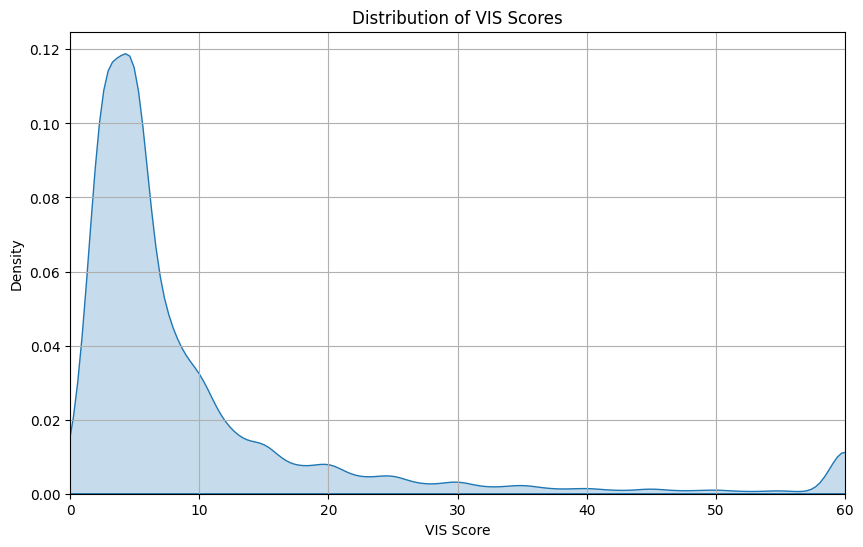

In [106]:
vis_data = training_data[training_data['vis'] > 0]['vis'].copy()

# let's squash vis to 10
x_lim = 60
# print proportion of values greater than 10
print(f"Proportion of VIS values greater than {x_lim}: {len(vis_data[vis_data > x_lim]) / len(vis_data):.4f}")

# clip vis_data at x_lim
vis_data = vis_data.clip(upper=x_lim)

print(f"Number of non-zero VIS entries: {len(vis_data)}")

# plot vis distribution as kde plot
plt.figure(figsize=(10, 6))
sns.kdeplot(vis_data, fill=True)
plt.title('Distribution of VIS Scores')
plt.xlabel('VIS Score')
plt.ylabel('Density')
plt.xlim(0, x_lim)
plt.grid(True)
plt.show()

Proportion of intake values greater than 400: 0.0135
Number of non-zero intake_data entries: 1995797


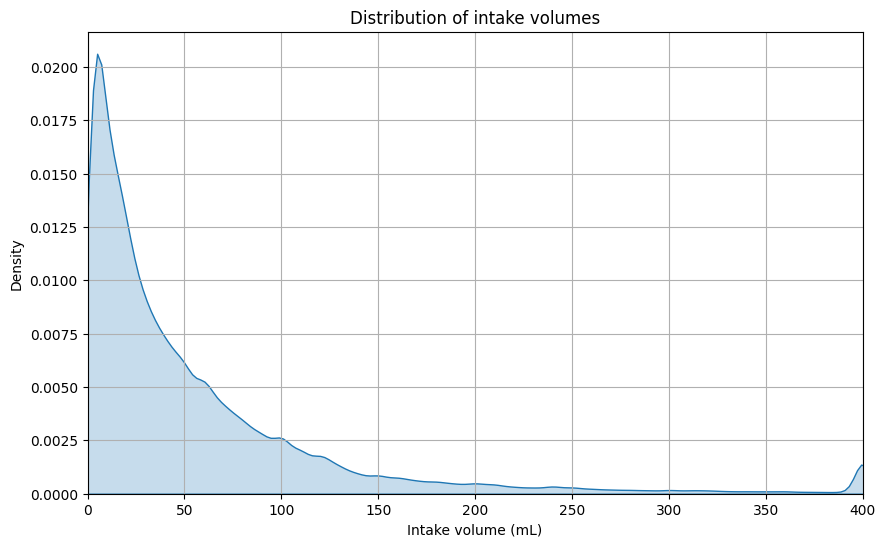

In [107]:
intake_data = training_data[training_data['intake'] > 0]['intake'].copy()

# let's squash vis to x_lim
x_lim = 400
# print proportion of values greater than 10
print(f"Proportion of intake values greater than {x_lim}: {len(intake_data[intake_data > x_lim]) / len(intake_data):.4f}")

# clip vis_data at x_lim
intake_data = intake_data.clip(upper=x_lim)

print(f"Number of non-zero intake_data entries: {len(intake_data)}")

# plot vis distribution as kde plot
plt.figure(figsize=(10, 6))
sns.kdeplot(intake_data, fill=True)
plt.title('Distribution of intake volumes')
plt.xlabel('Intake volume (mL)')
plt.ylabel('Density')
plt.xlim(0, x_lim)
plt.grid(True)
plt.show()

In [ ]:
# create dictionary of min and max values for each feature
feature_min_max = {
    'fio2': (0.21, 1.0),
    'mean_airway_pressure': (5, 30),
    'airway_type': (0, 2),  # Categorical, but keep range for heatmap
    'oxygen_flow': (0, 30),
    'random_glucose': (20, 400),
    'calcium': (5, 13),
    'potassium': (2, 8),
    'crp': (0, 300),
    'white_blood_cell_count': (0, 40),
    'creatinine': (0.1, 2),
    'neutrophil_percent': (0, 100),
    'blood_pressure_systolic': (25, 175),
    'blood_pressure_diastolic': (10, 115),
    'heart_rate': (40, 200),
    'temperature': (36, 40),
    'oxygen_saturation': (70, 100),
    'respiratory_rate': (5, 100),
    'vis': (0, 30),  # Vasoactive-Inotropic Score
    'intake': (0, 200),
    'health_score': (0, 2)
}

In [109]:
# loop through the feature_min_max dictionary, and for each feature, clip the values in training_data to the min and max values
# and then min max scale the values to be between 0 and 1
for feature, (min_val, max_val) in feature_min_max.items():
    training_data[feature] = training_data[feature].clip(lower=min_val, upper=max_val)
    training_data[feature] = (training_data[feature] - min_val) / (max_val - min_val)   

training_data.head()

,MASKED_ENCNTR_ID,EVENT_END_DT_TM,fio2,mean_airway_pressure,airway_type,oxygen_flow,random_glucose,calcium,potassium,crp,...,neutrophil_percent,blood_pressure_systolic,blood_pressure_diastolic,heart_rate,temperature,oxygen_saturation,respiratory_rate,vis,intake,health_score
0,1165293630,2239-06-12 00:00:00,0.0,0.0,0.0,0.0,0.176316,0.2500,0.150000,0.024,...,0.08,0.300000,0.266667,0.6250,0.350000,0.866667,0.431579,0.0,0.000000,0.517763
1,1165293630,2239-06-12 01:00:00,0.0,0.0,0.0,0.0,0.176316,0.2500,0.150000,0.024,...,0.08,0.311111,0.260317,0.5125,0.358333,0.800000,0.284211,0.0,0.000000,0.517083
2,1165293630,2239-06-12 02:00:00,0.0,0.0,0.0,0.0,0.176316,0.2500,0.150000,0.024,...,0.08,0.322222,0.253968,0.6250,0.366667,0.633333,0.442105,0.0,0.062500,0.518912
3,1165293630,2239-06-12 03:00:00,0.0,0.0,0.0,0.0,0.171579,0.2525,0.171429,0.024,...,0.08,0.333333,0.247619,0.5750,0.375000,0.866667,0.526316,0.0,0.070000,0.519382
4,1165293630,2239-06-12 04:00:00,0.0,0.0,0.0,0.0,0.166842,0.2550,0.192857,0.024,...,0.08,0.233333,0.323810,0.6250,0.362500,1.000000,0.463158,0.0,0.074875,0.518577


In [137]:
plt.rcParams.update({
    'font.size': 20,           # Default text size
    'axes.titlesize': 24,      # Title font size
    'axes.labelsize': 20,      # Axis label font size
    'xtick.labelsize': 18,     # X tick label size
    'ytick.labelsize': 18,     # Y tick label size
    'legend.fontsize': 18,     # Legend font size
    'figure.titlesize': 26     # Figure title size
})

In [142]:
def plot_encounter_heatmap(training_data, non_survivor_ids, encounter_id, plot_dir=None):
    """
    """

    print(f"Using example encounter ID: {encounter_id}")

    # check if encounter_id is in non_survivor_ids
    if encounter_id in non_survivor_ids:
        outcome = "non-survivor"
        print(f"Encounter ID {encounter_id} is a non-survivor.")
    else:
        outcome = "survivor"
        print(f"Encounter ID {encounter_id} is a survivor.")

    # training featrues 
    example_training_traj = training_data[training_data['MASKED_ENCNTR_ID'] == encounter_id]

    # drop the MASKED_ENCNTR_ID and EVENT_END_DT_TM columns
    example_training_traj = example_training_traj.drop(columns=['MASKED_ENCNTR_ID', 'EVENT_END_DT_TM'])

    # fill NaN values (if any) with 0
    example_training_traj = example_training_traj.fillna(0)

    # 2. Transpose so features are rows, timepoints are columns
    heatmap_data = example_training_traj.T

    # Set x-axis to days (assuming each column is an hour)
    n_timepoints = heatmap_data.shape[1]

    # 3. Plot heatmap
    plt.figure(figsize=(19.2, 10.8), dpi=100)
    sns.heatmap(heatmap_data, cmap='viridis', cbar=True)
    plt.xlabel("Time (days)")
    plt.ylabel("Feature")
    plt.title("Normalized Feature Trajectory - encounter ID: {} ({})".format(encounter_id, outcome))

    # Set x-ticks every 24 timepoints (every day)
    xtick_positions = list(range(0, n_timepoints, 24))
    xtick_labels = [int(i / 24) for i in xtick_positions]

    if len(xtick_positions) > 30:
        while len(xtick_positions) > 30:
            xtick_positions = xtick_positions[::2]
            xtick_labels = xtick_labels[::2]

    plt.xticks(ticks=xtick_positions, labels=xtick_labels)

    plt.tight_layout()

    # Save the plot if plot_dir is provided
    if plot_dir:
        os.makedirs(plot_dir, exist_ok=True)
        plot_path = os.path.join(plot_dir, f"encounter_id_{encounter_id}_{outcome}.png")
        plt.savefig(plot_path)
        print(f"Heatmap saved to {plot_path}")

    plt.show()

    return example_training_traj


In [143]:
plot_dir = "/home/jake/Documents/AI_Clinician/experiments/health_score_trajectories"

Using example encounter ID: 1165397252
Encounter ID 1165397252 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1165397252_survivor.png


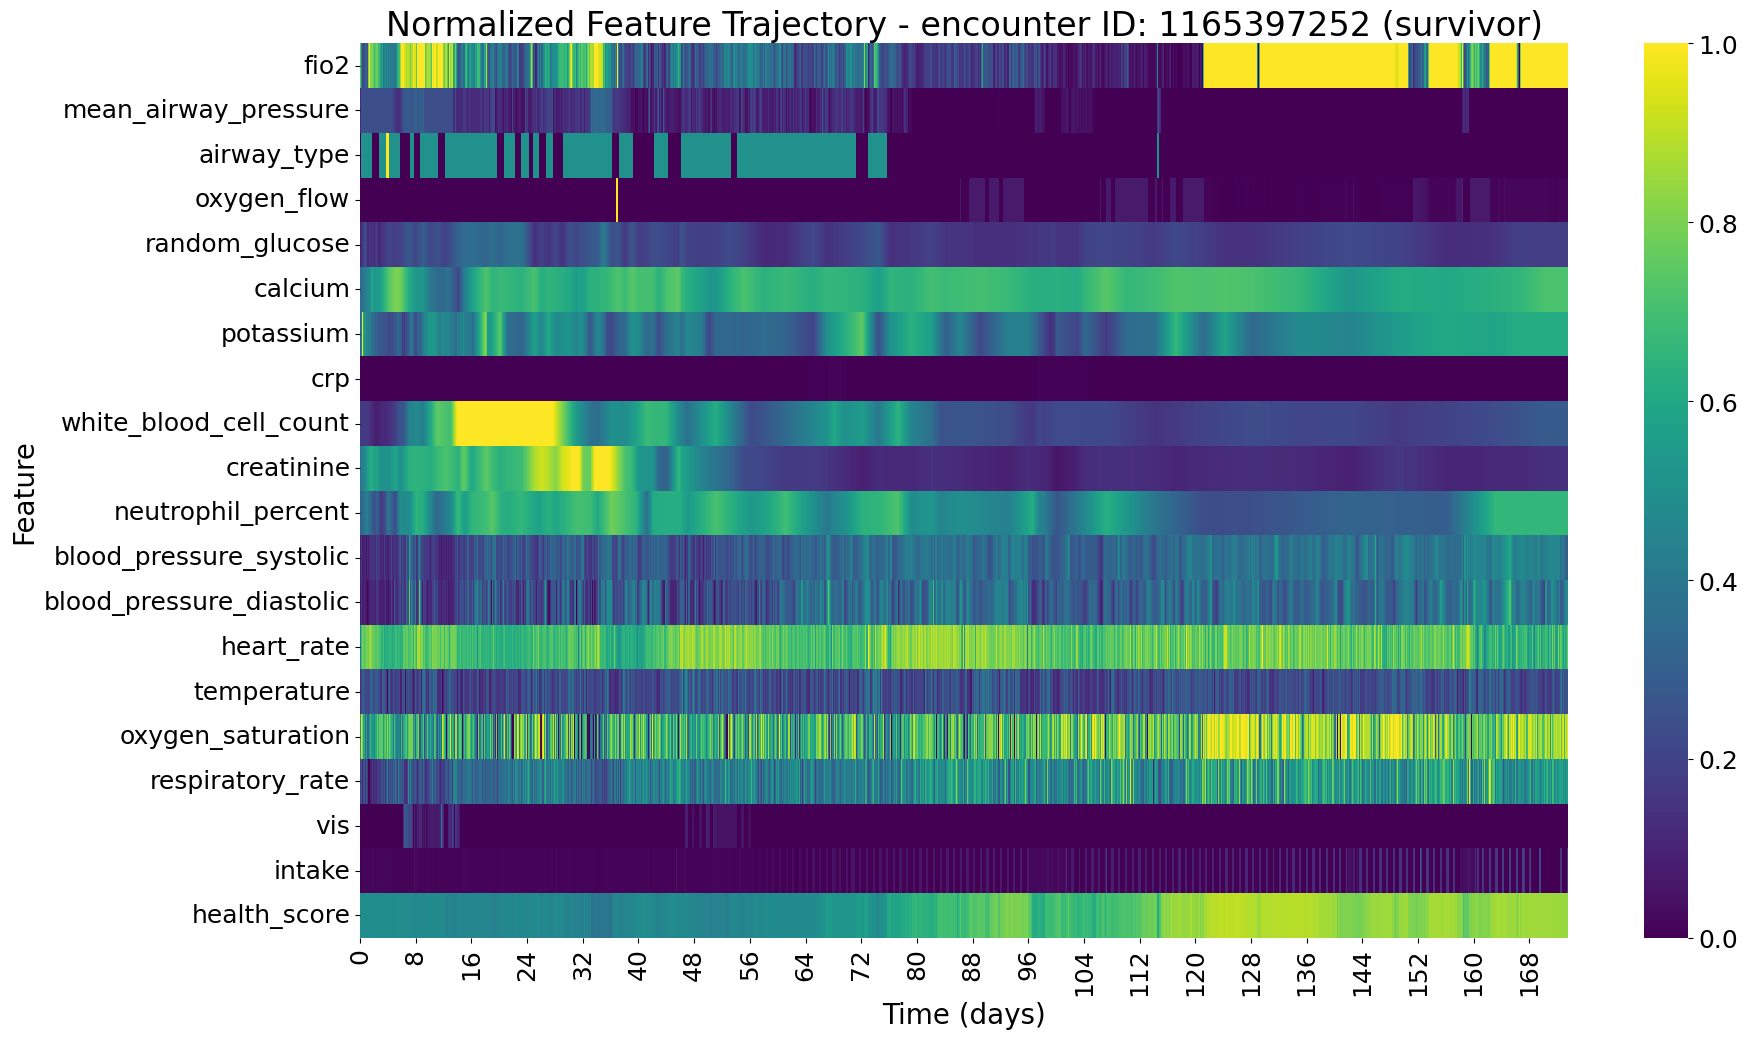

Using example encounter ID: 1165608832
Encounter ID 1165608832 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1165608832_survivor.png


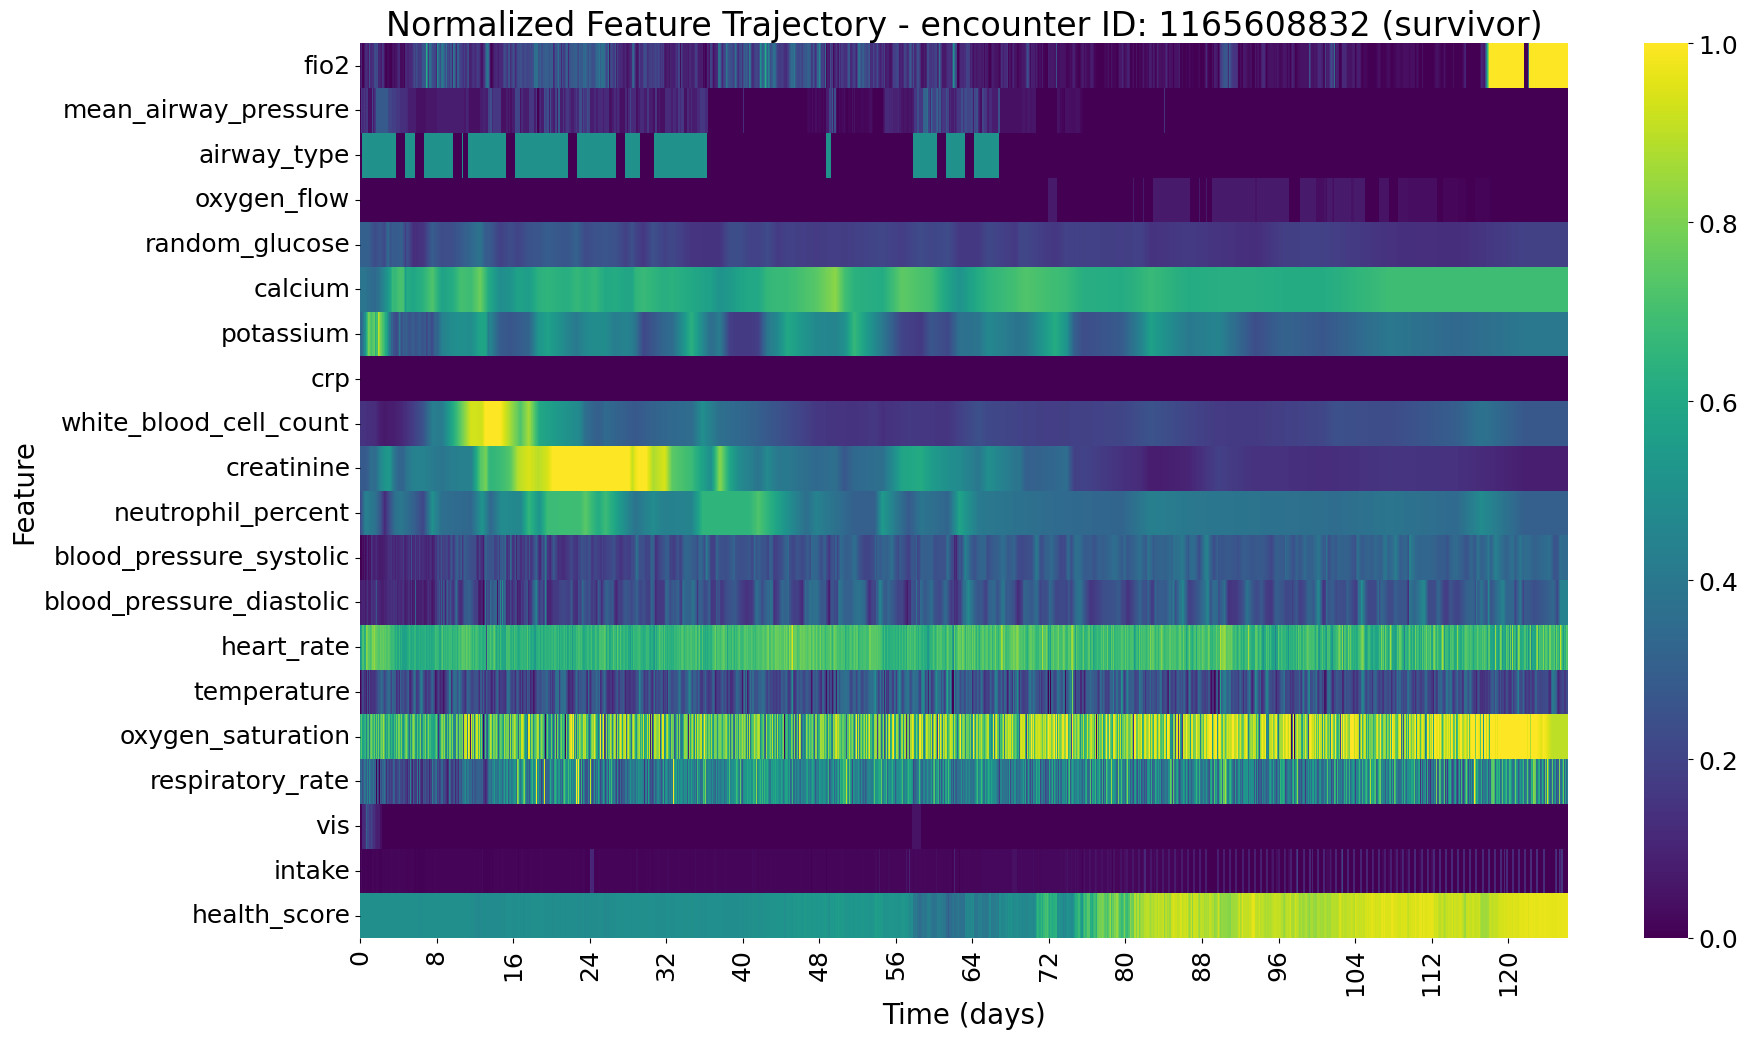

Using example encounter ID: 1165746083
Encounter ID 1165746083 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1165746083_survivor.png


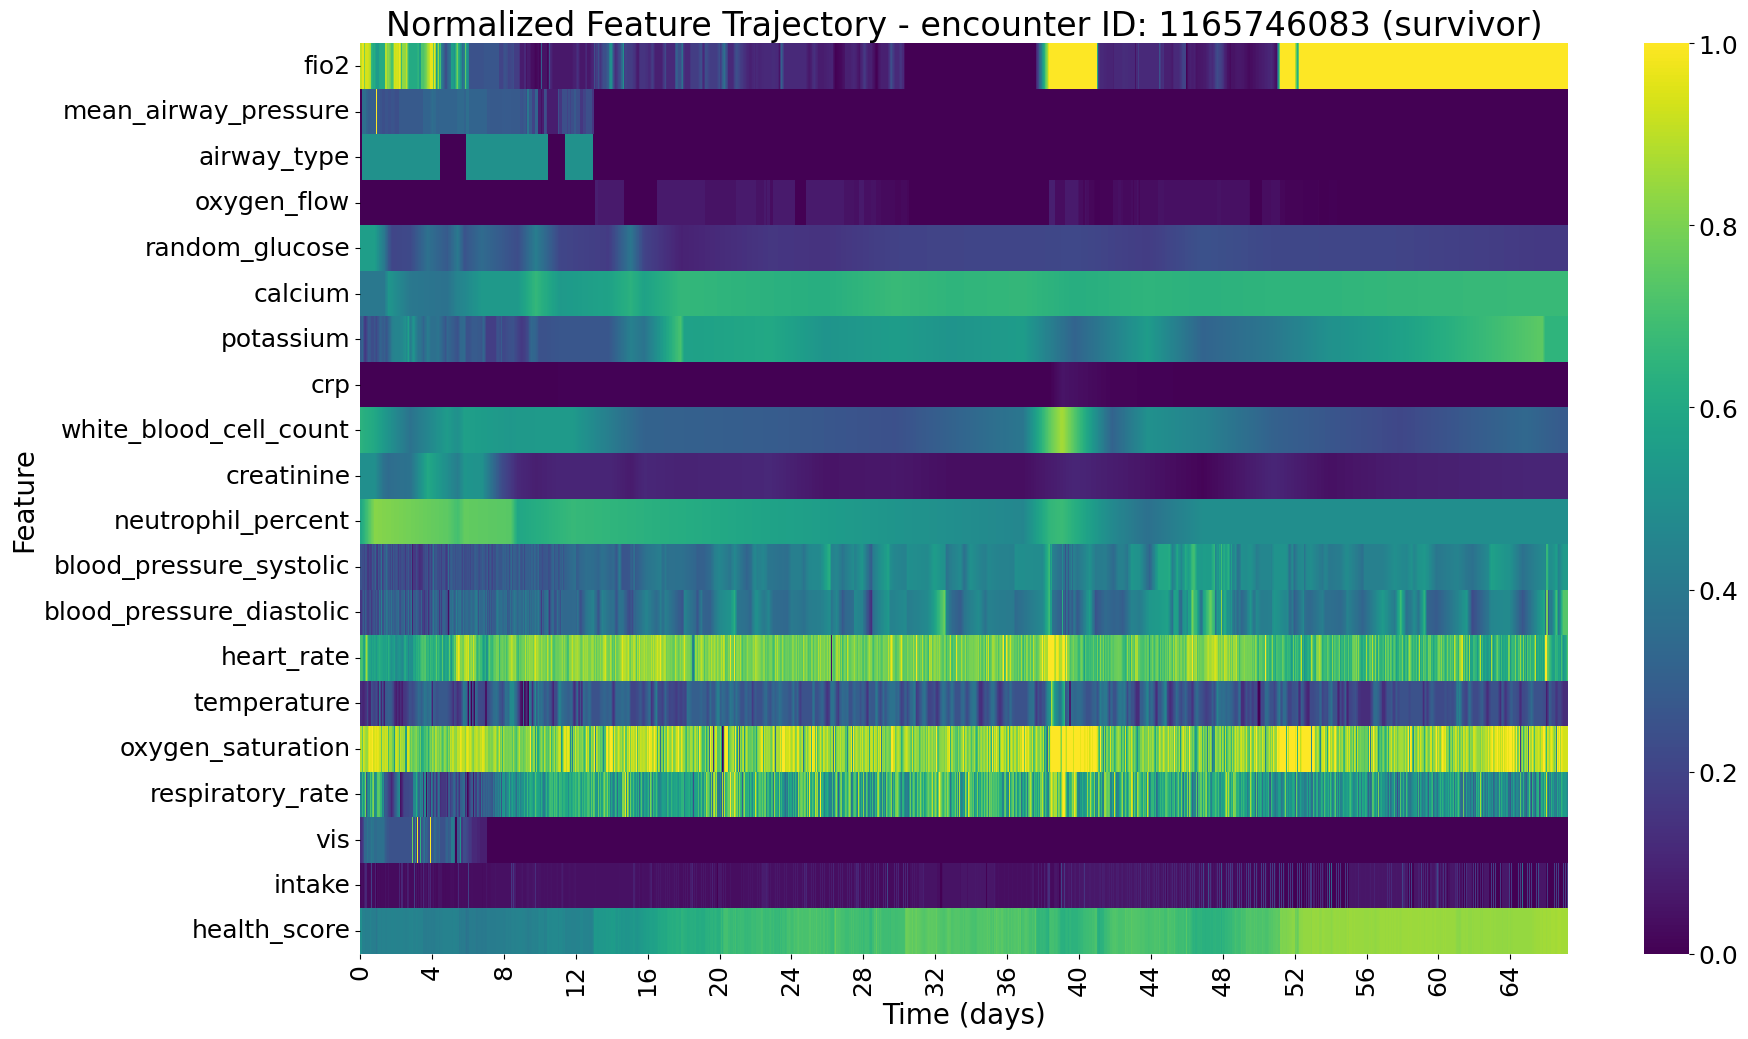

Using example encounter ID: 1165842435
Encounter ID 1165842435 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1165842435_survivor.png


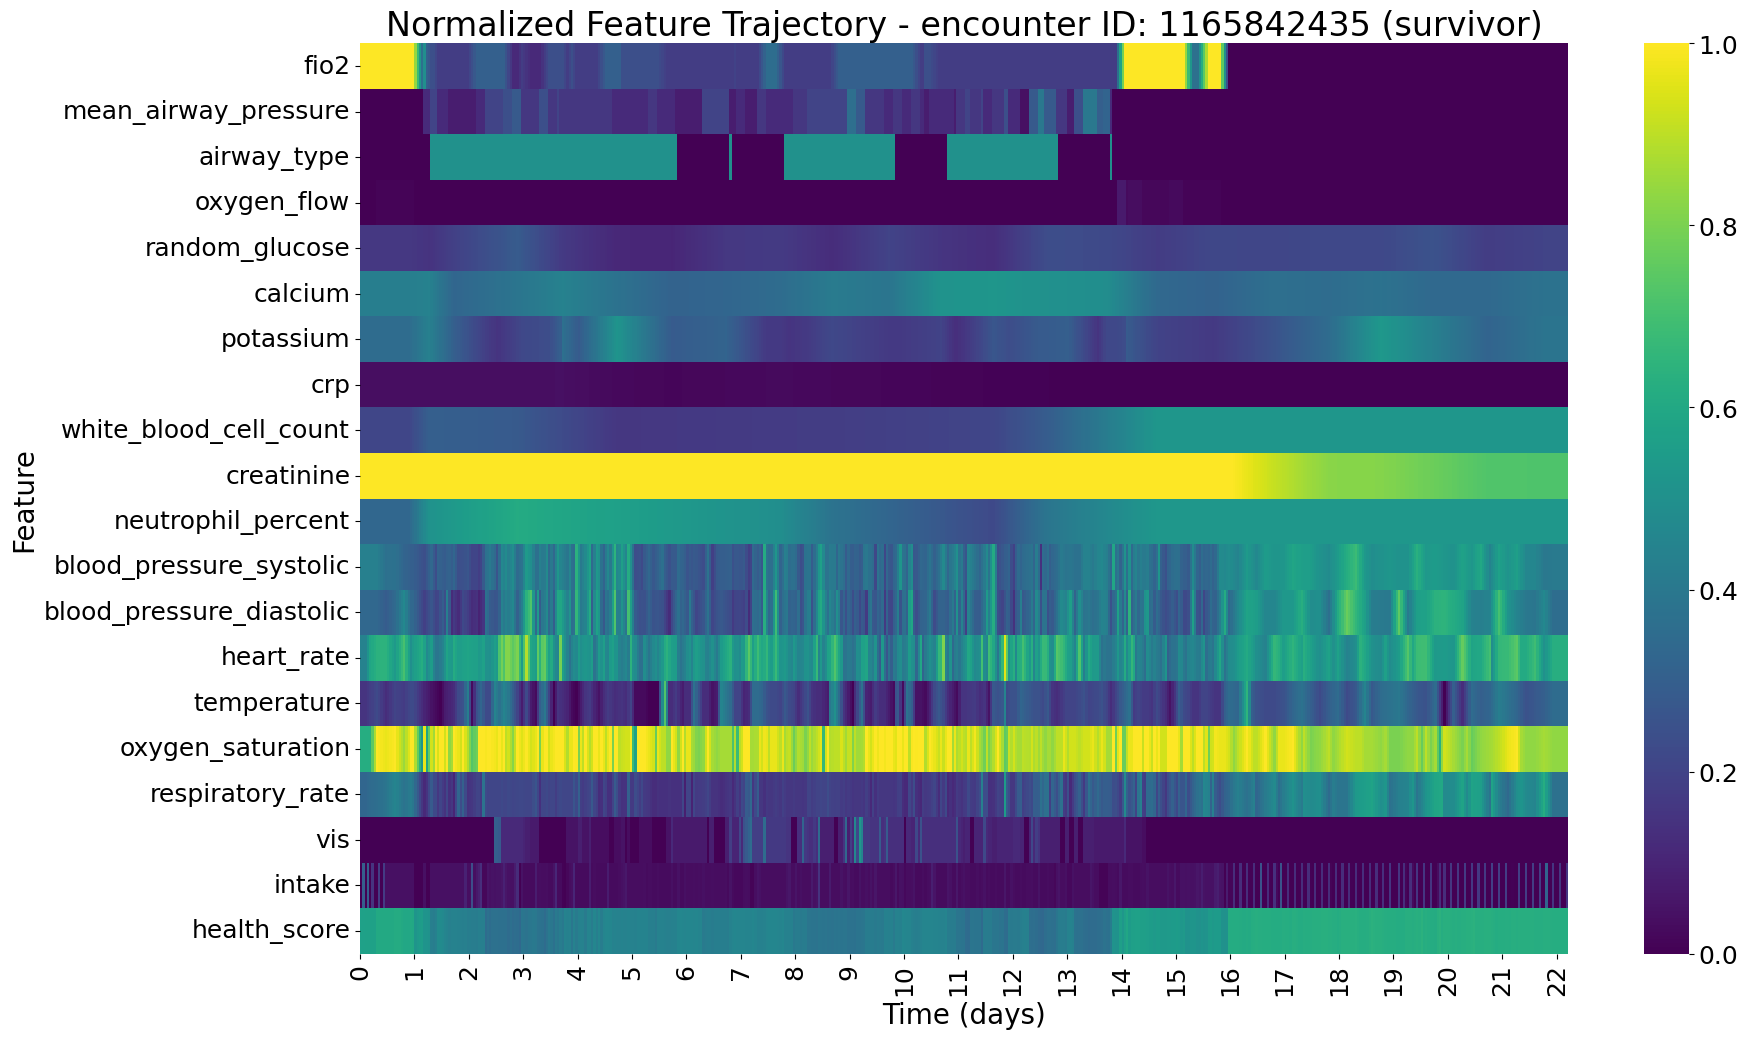

Using example encounter ID: 1165872386
Encounter ID 1165872386 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1165872386_survivor.png


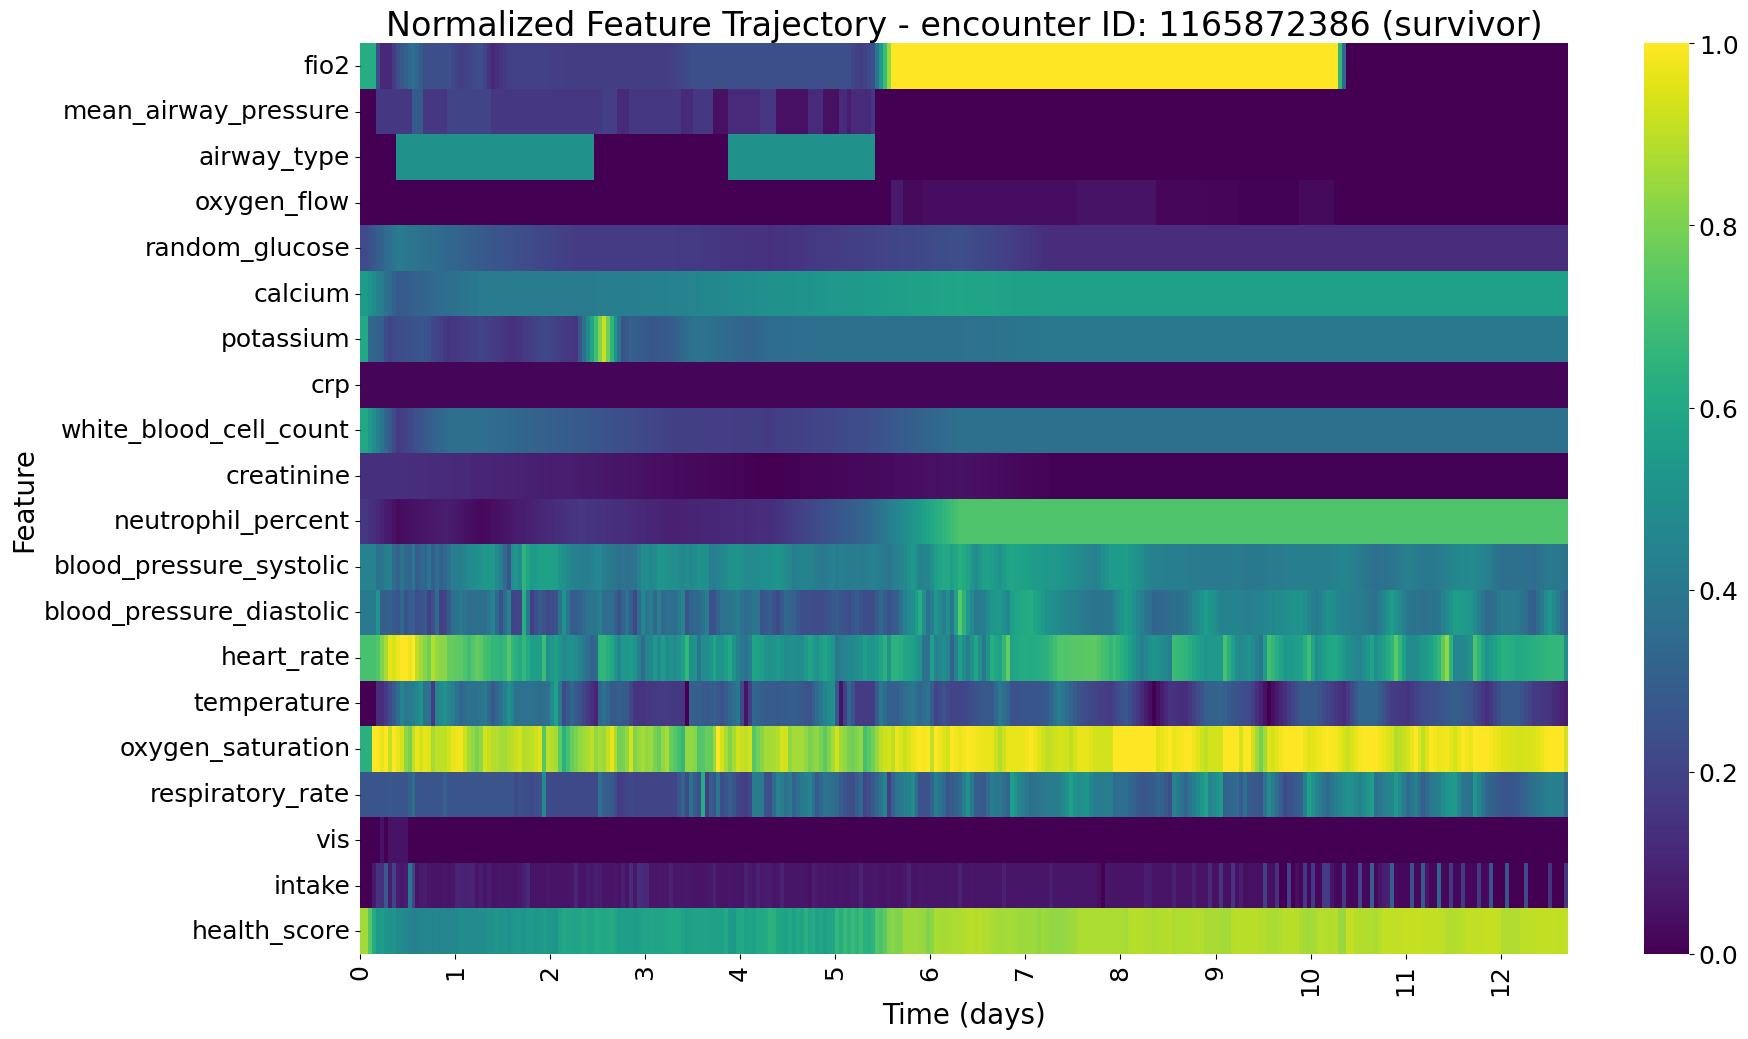

Using example encounter ID: 1165881806
Encounter ID 1165881806 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1165881806_survivor.png


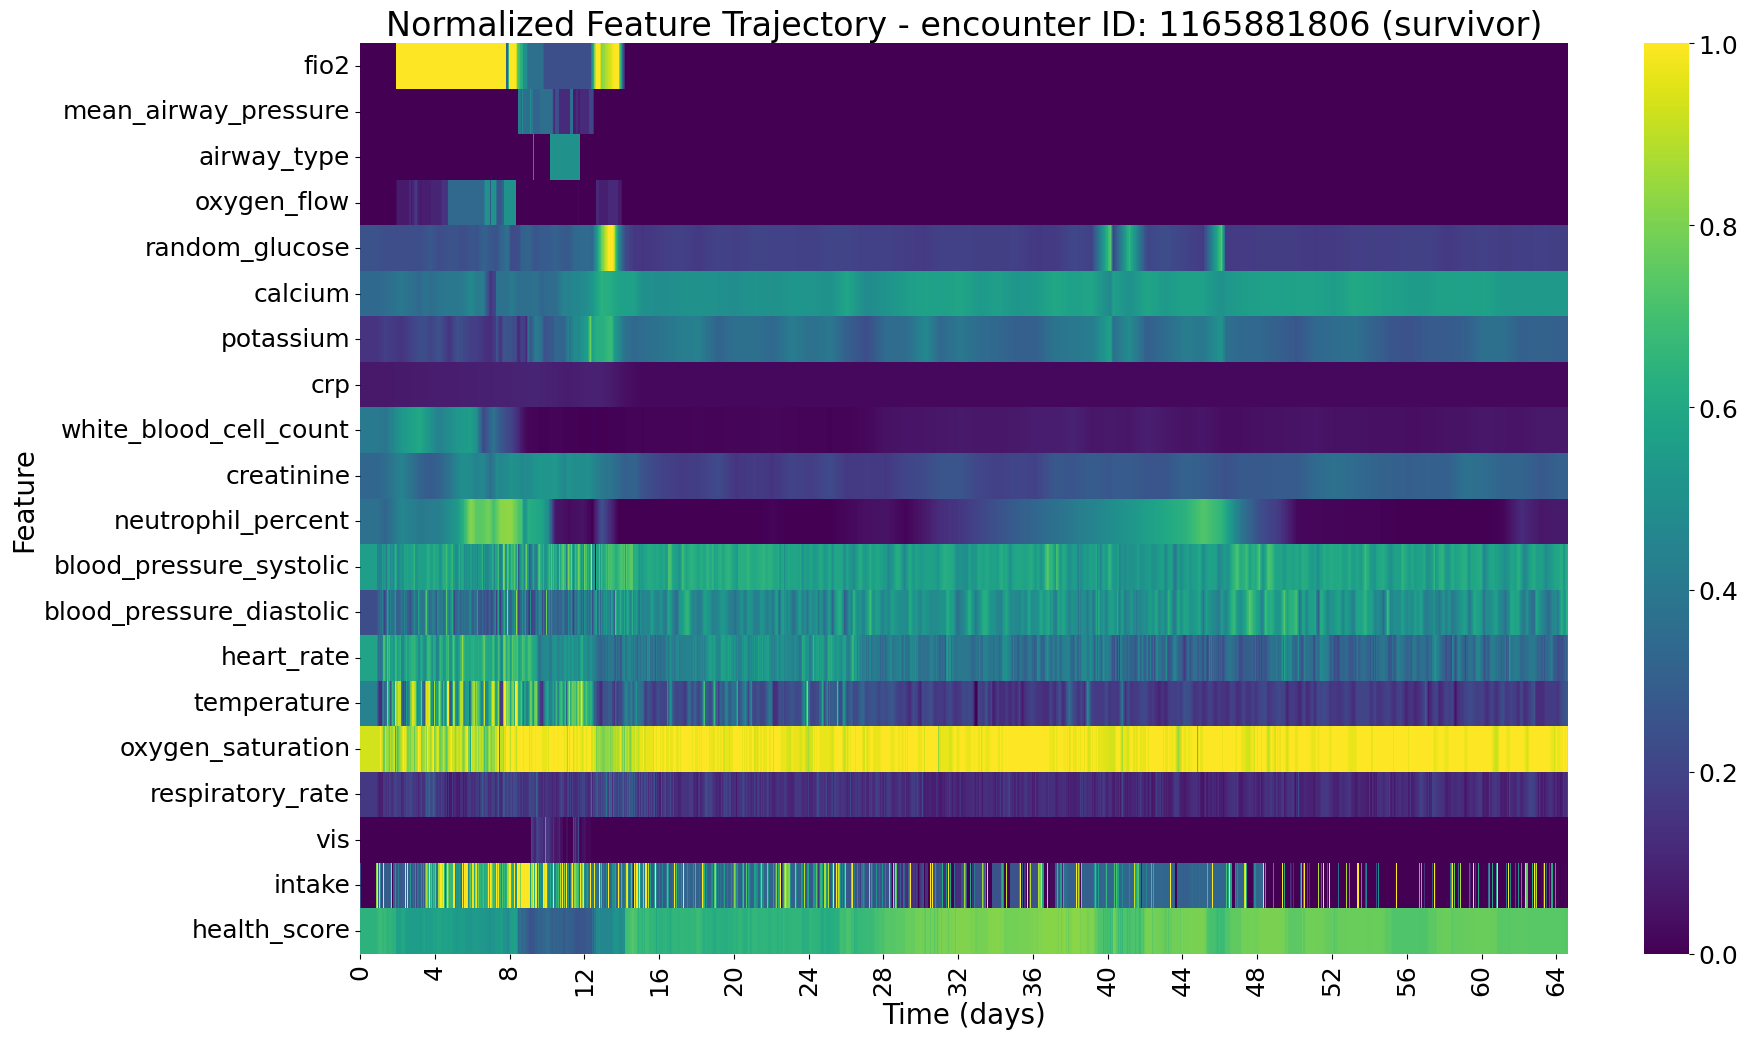

Using example encounter ID: 1165892898
Encounter ID 1165892898 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1165892898_survivor.png


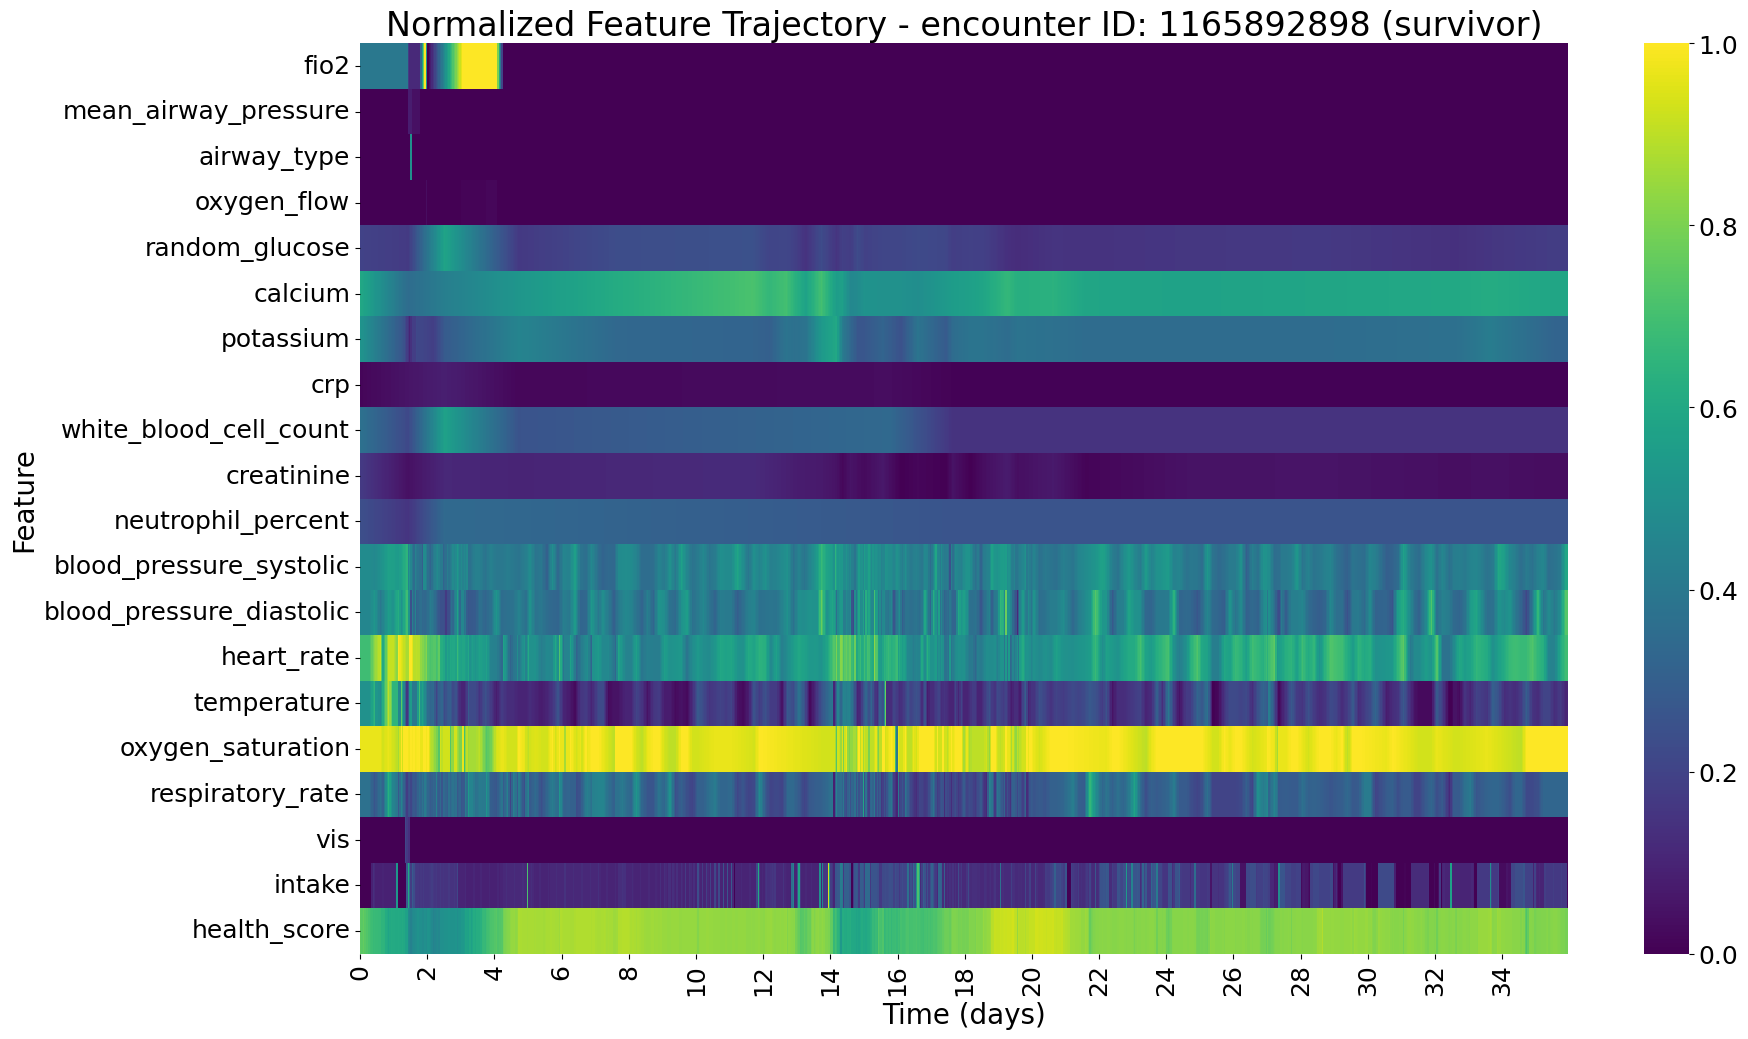

Using example encounter ID: 1165893034
Encounter ID 1165893034 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1165893034_survivor.png


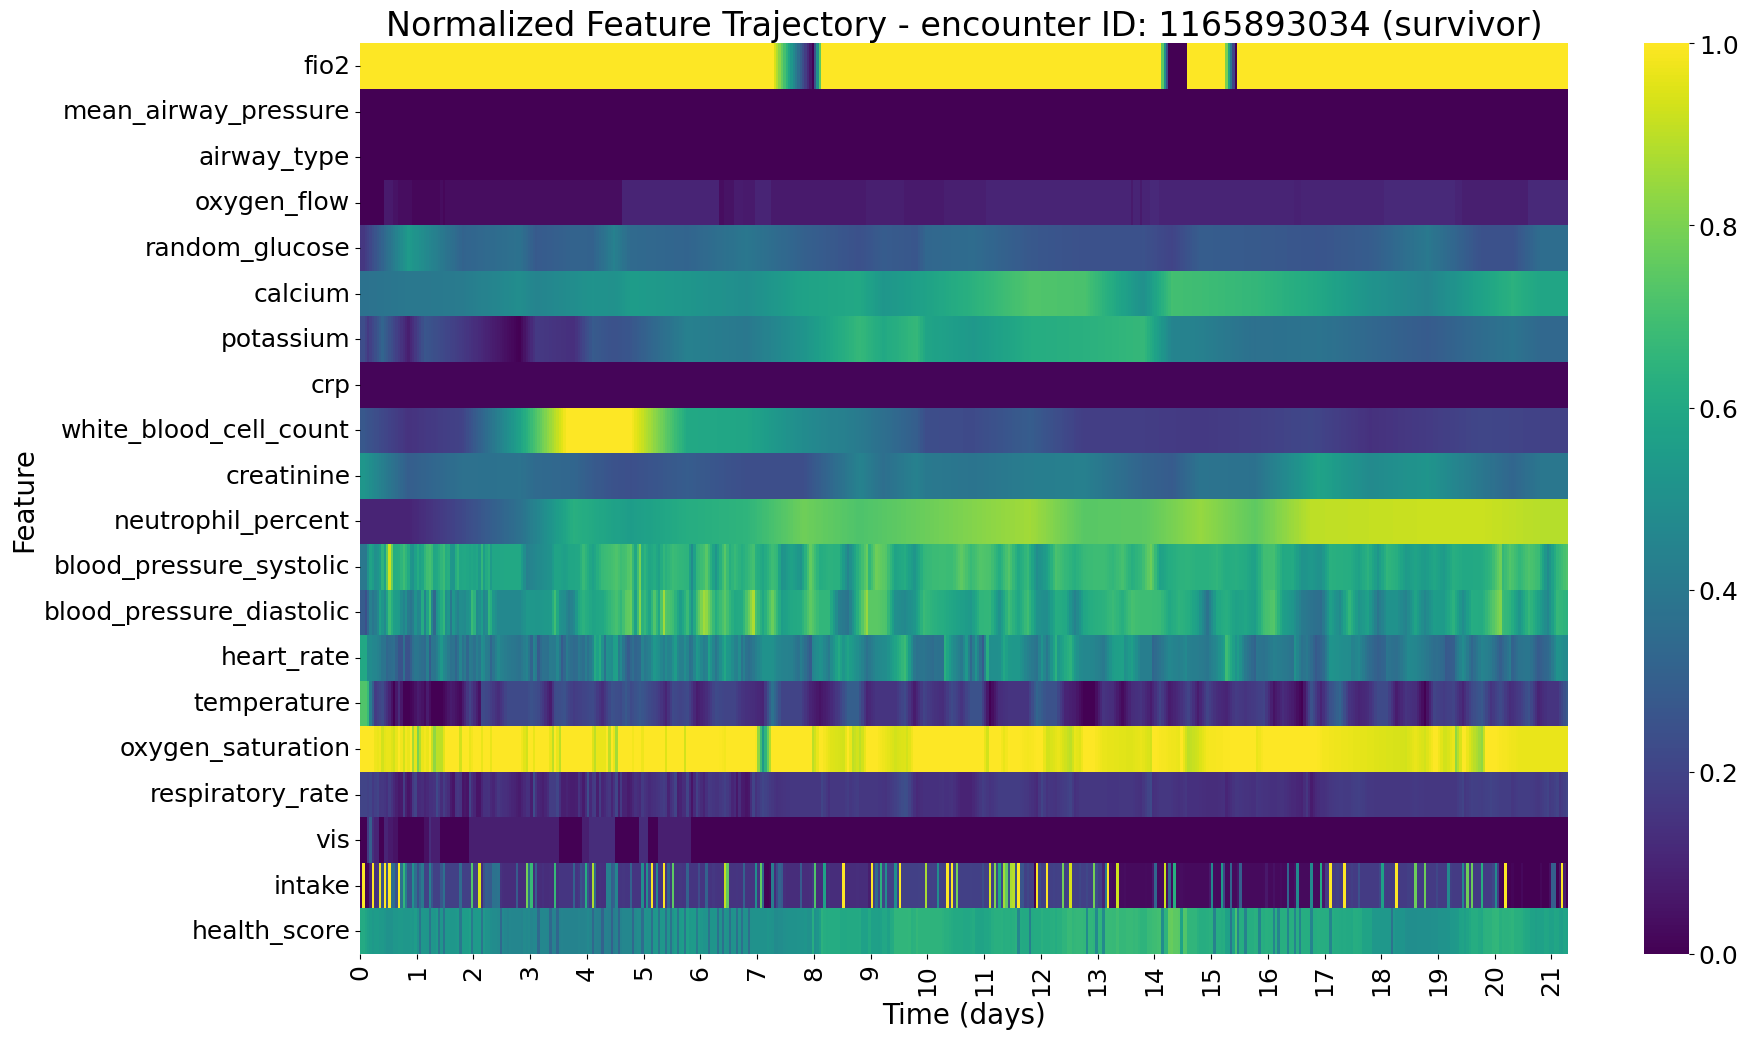

Using example encounter ID: 1165959412
Encounter ID 1165959412 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1165959412_survivor.png


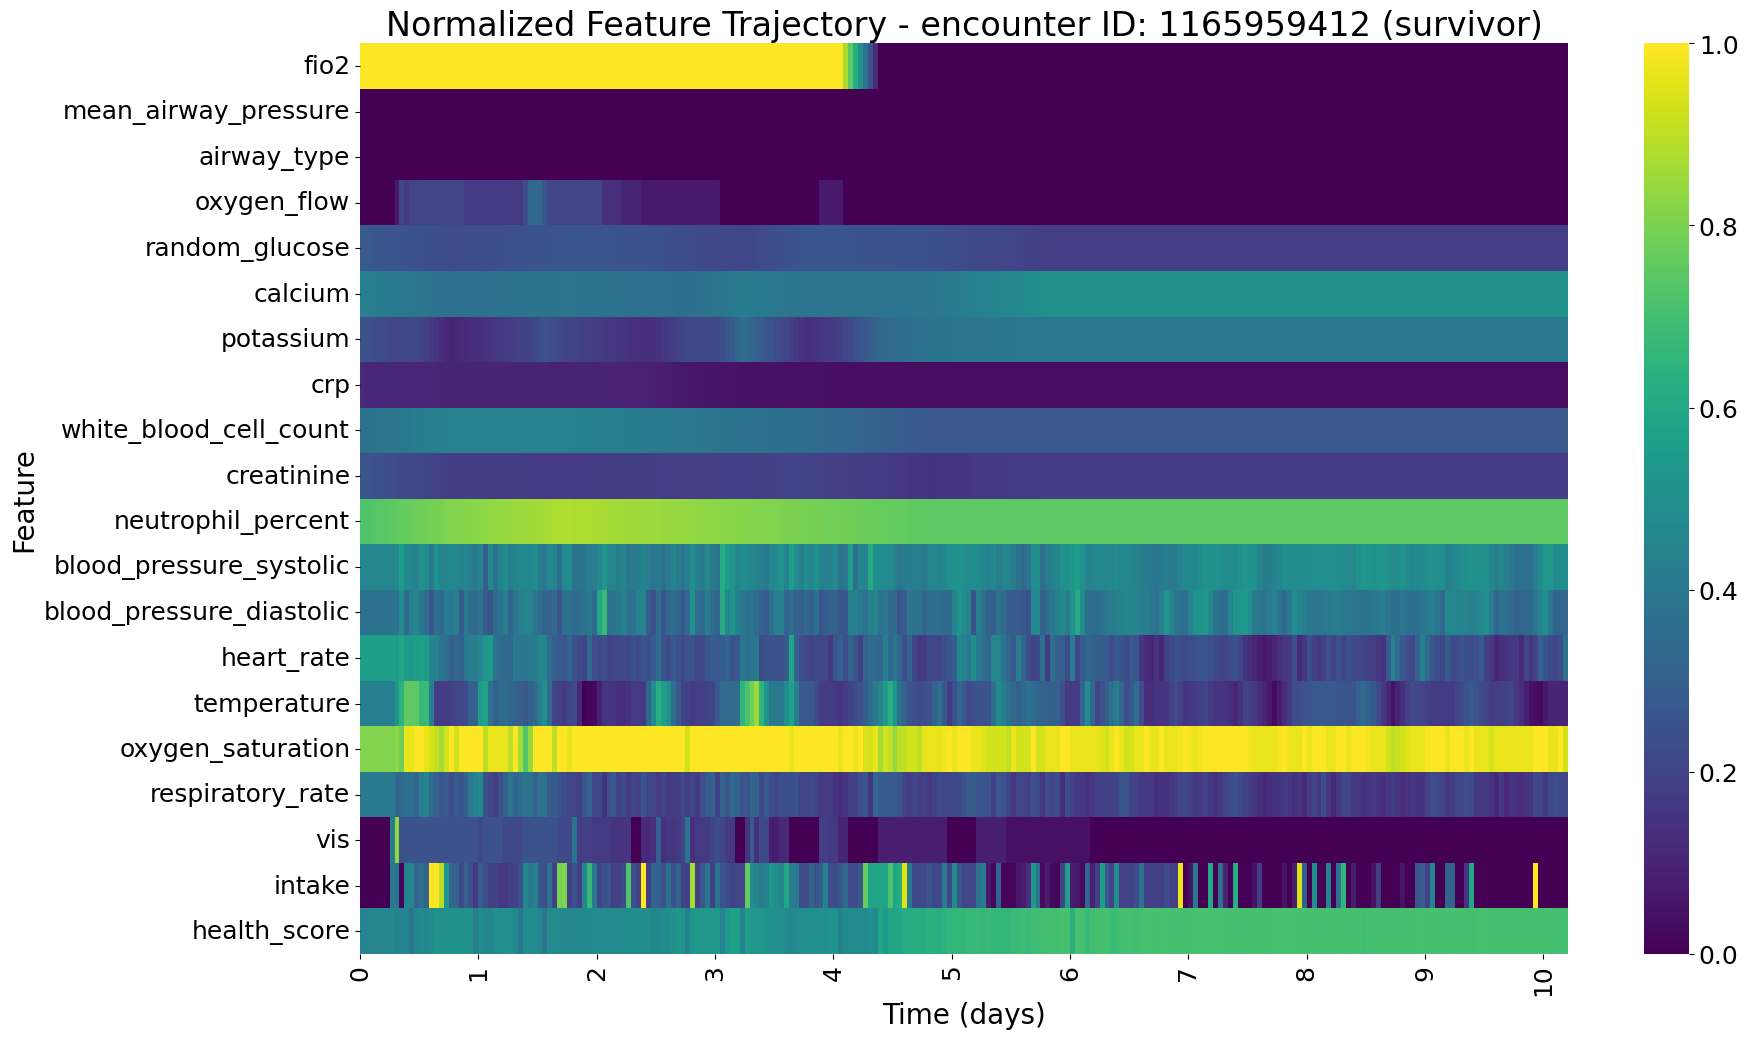

Using example encounter ID: 1165992819
Encounter ID 1165992819 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1165992819_survivor.png


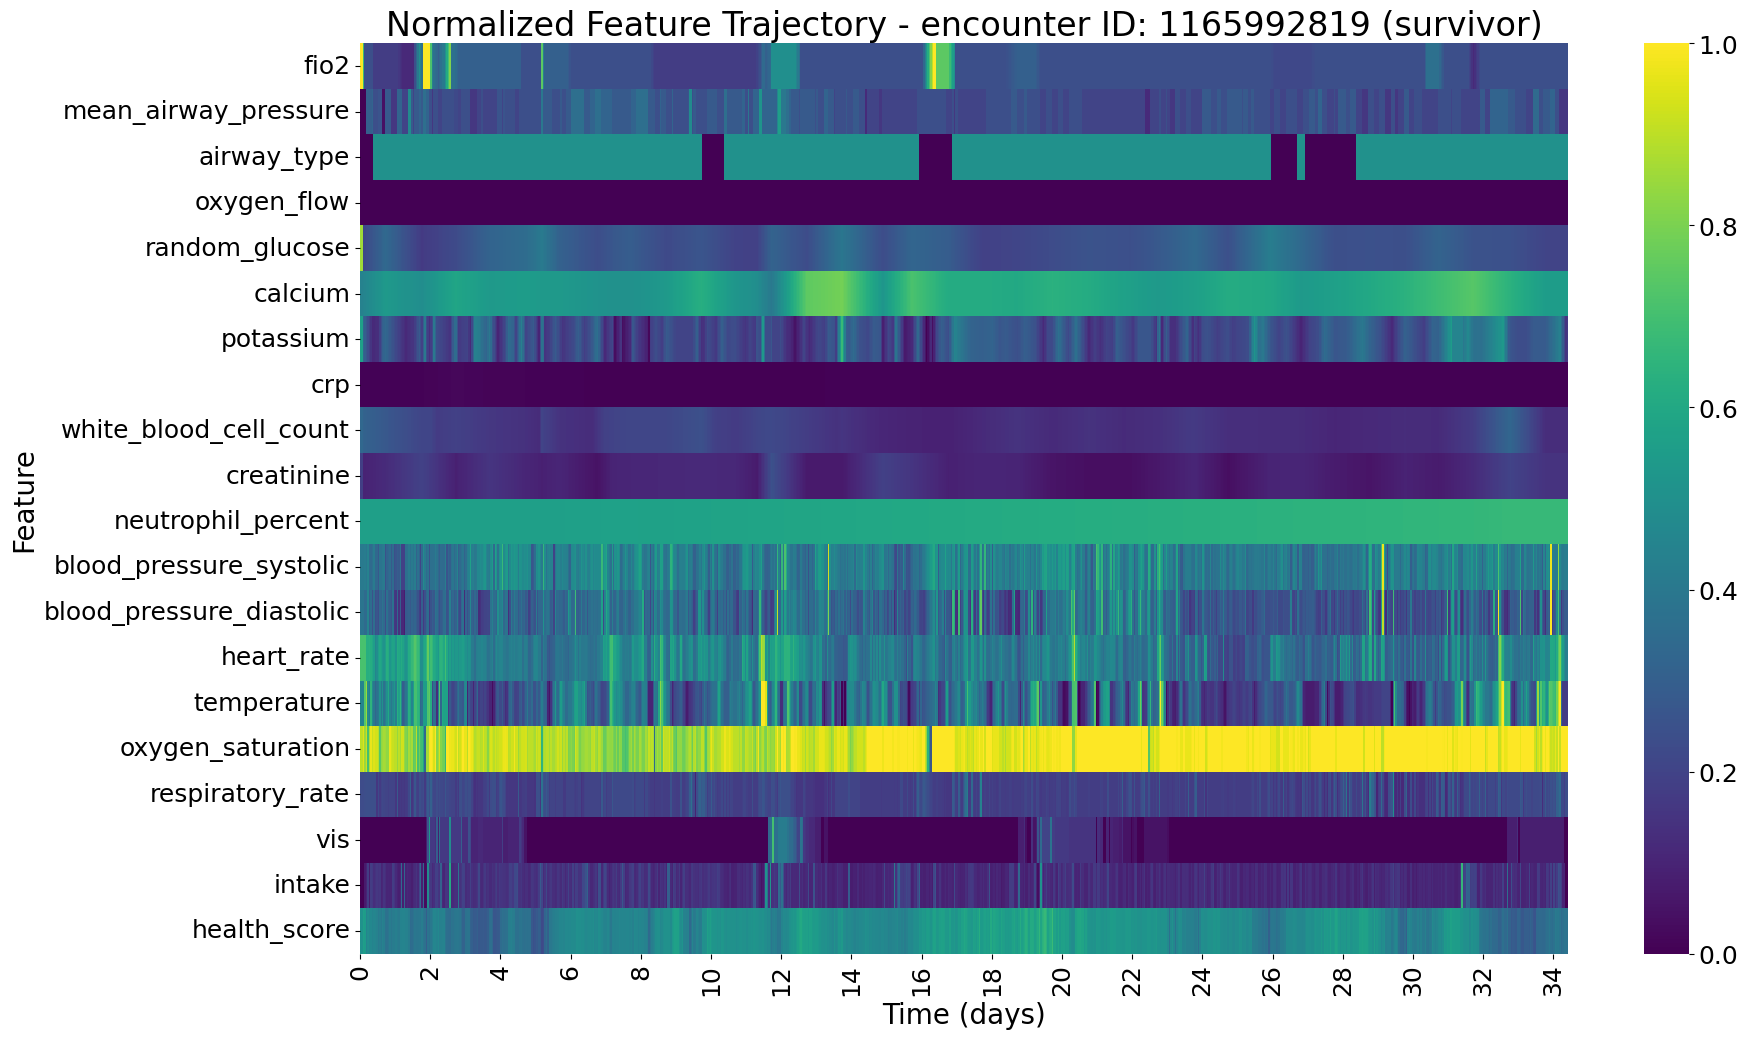

Using example encounter ID: 1166016271
Encounter ID 1166016271 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1166016271_survivor.png


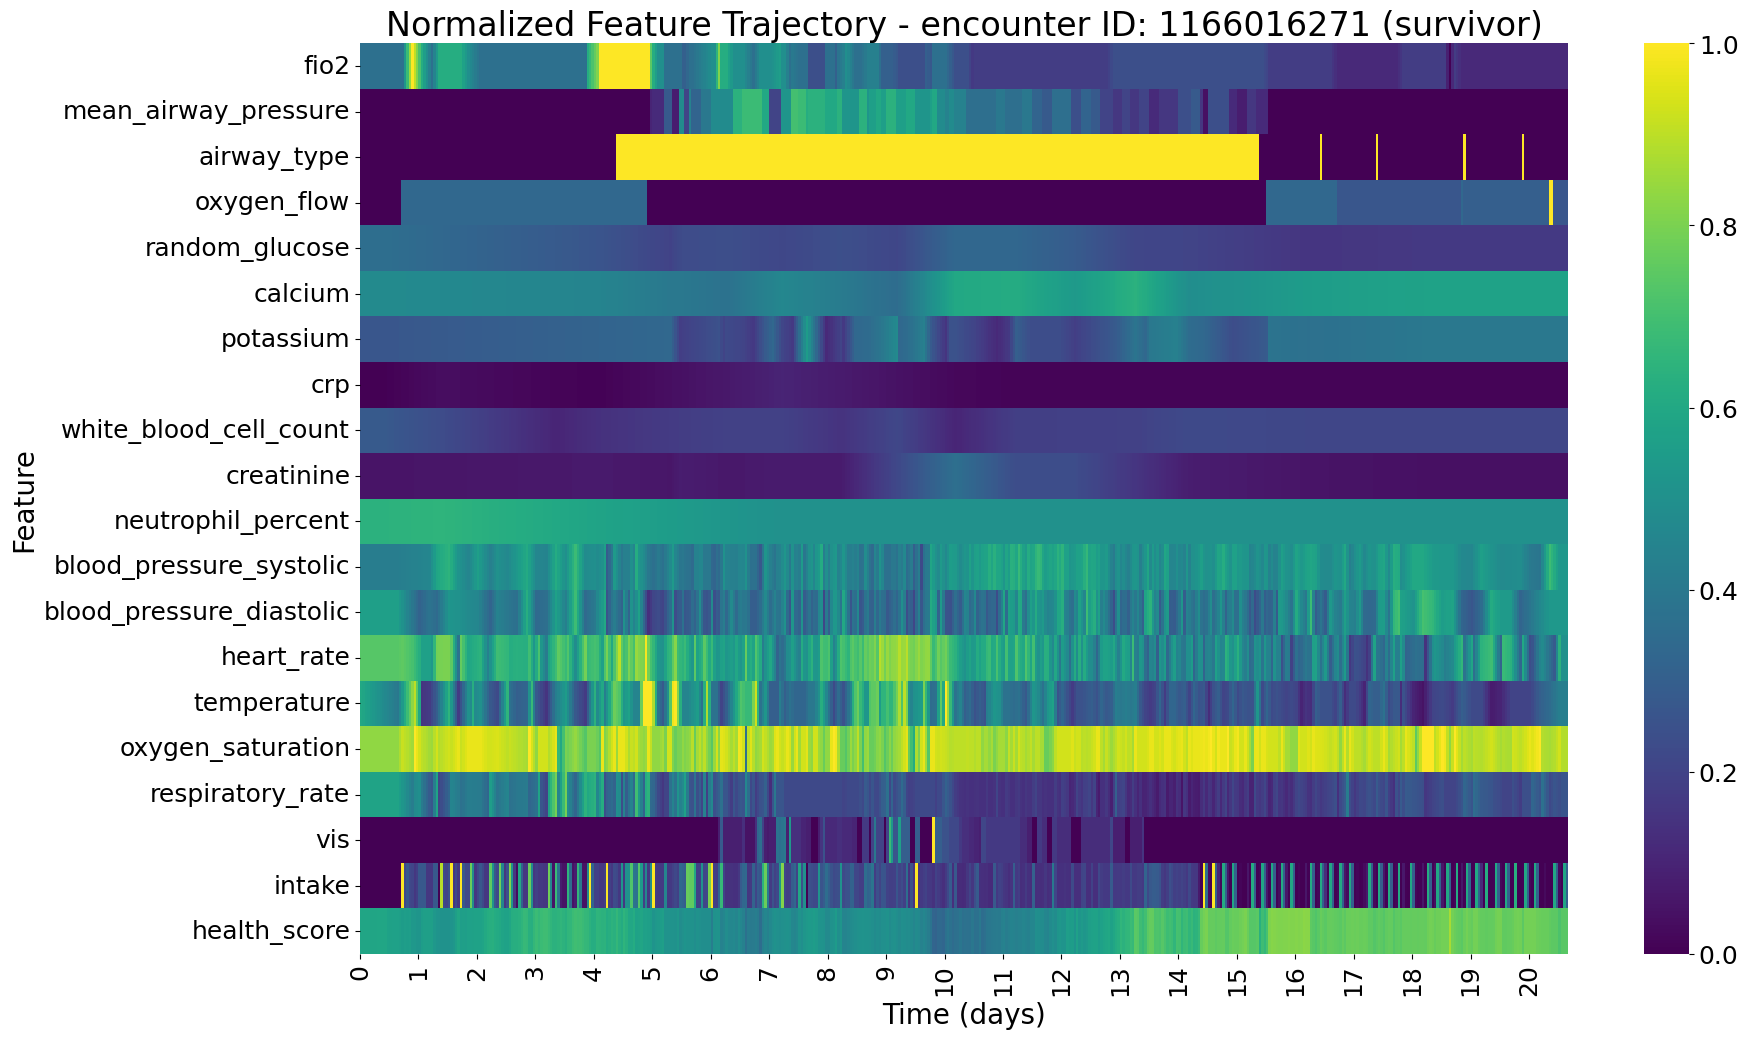

Using example encounter ID: 1166081806
Encounter ID 1166081806 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1166081806_survivor.png


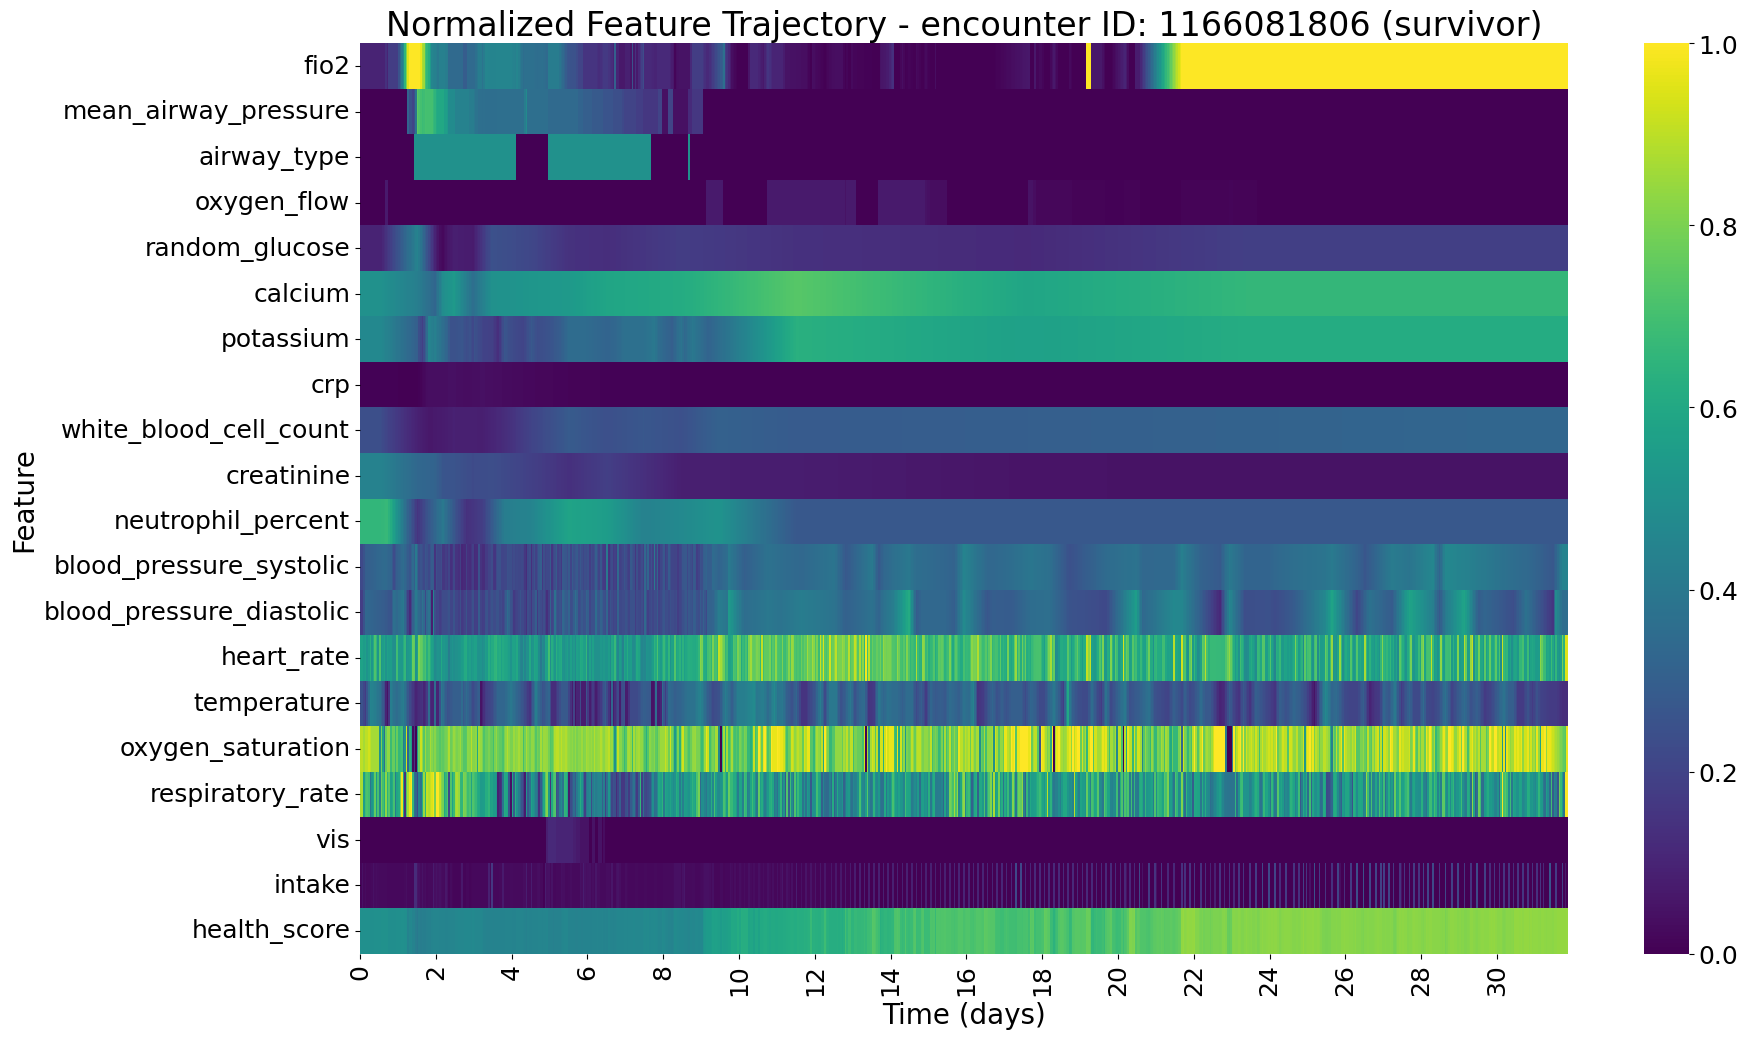

Using example encounter ID: 1166182411
Encounter ID 1166182411 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1166182411_survivor.png


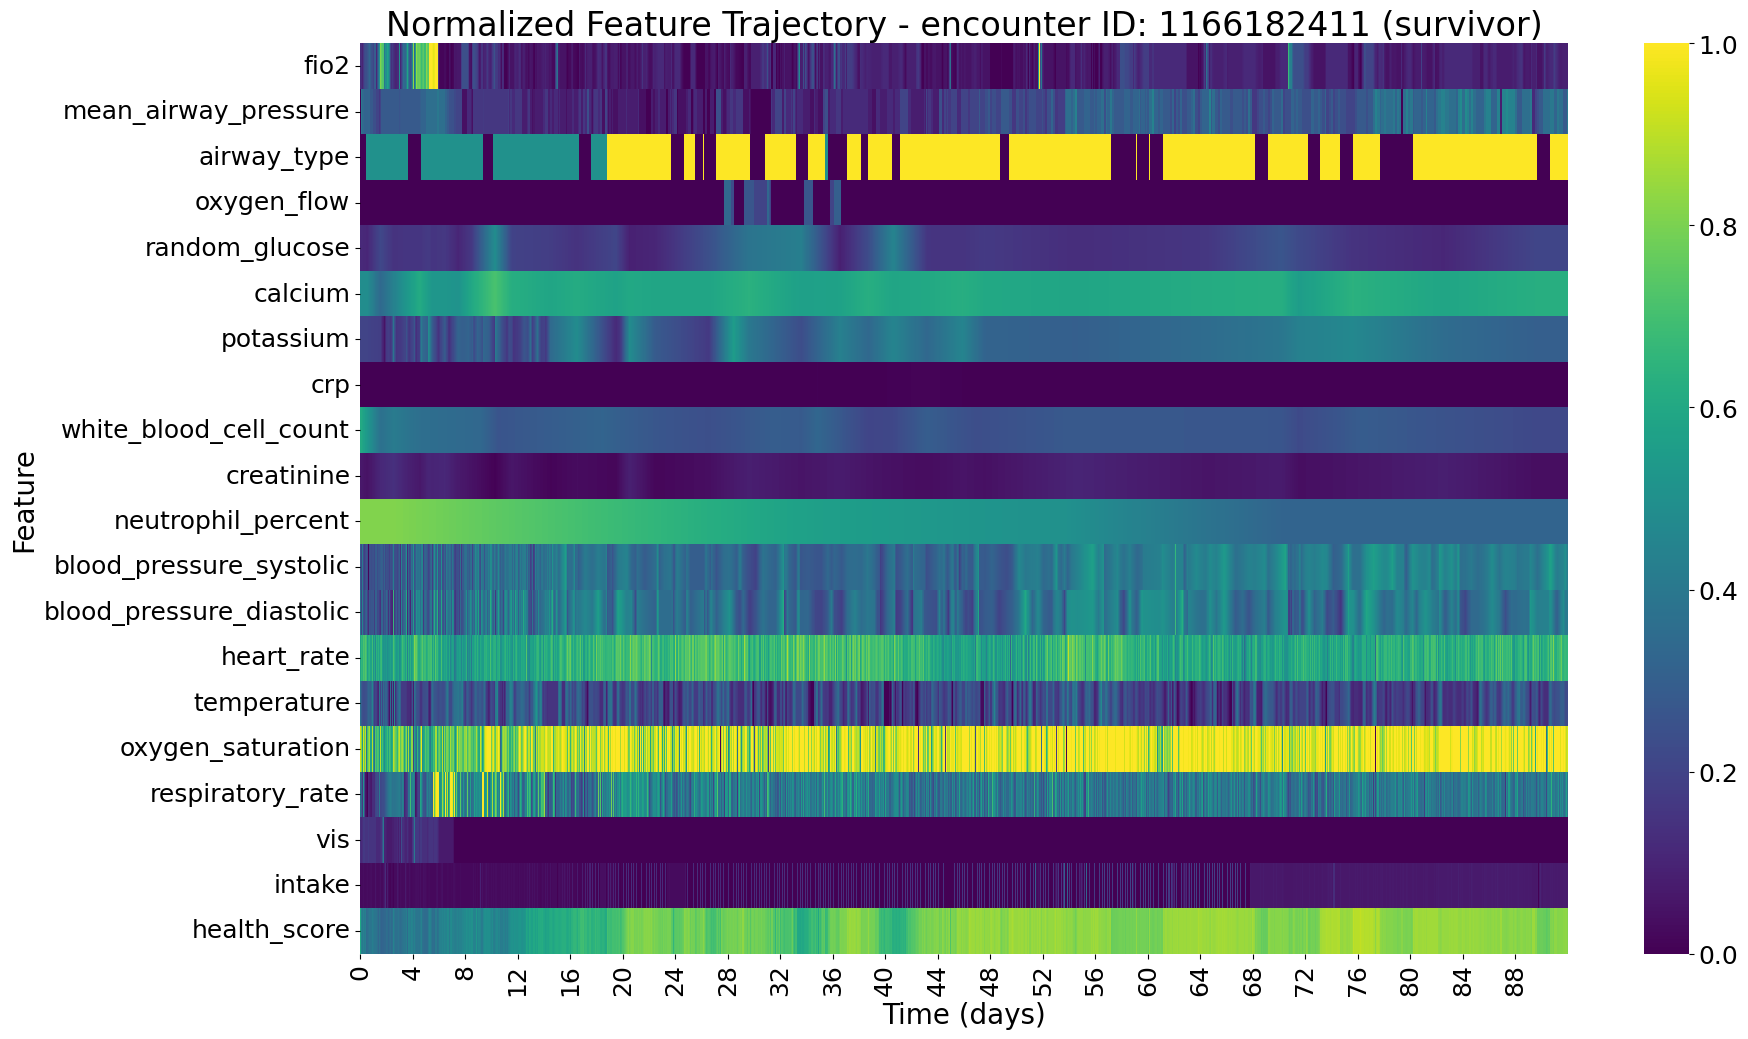

Using example encounter ID: 1166197098
Encounter ID 1166197098 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1166197098_survivor.png


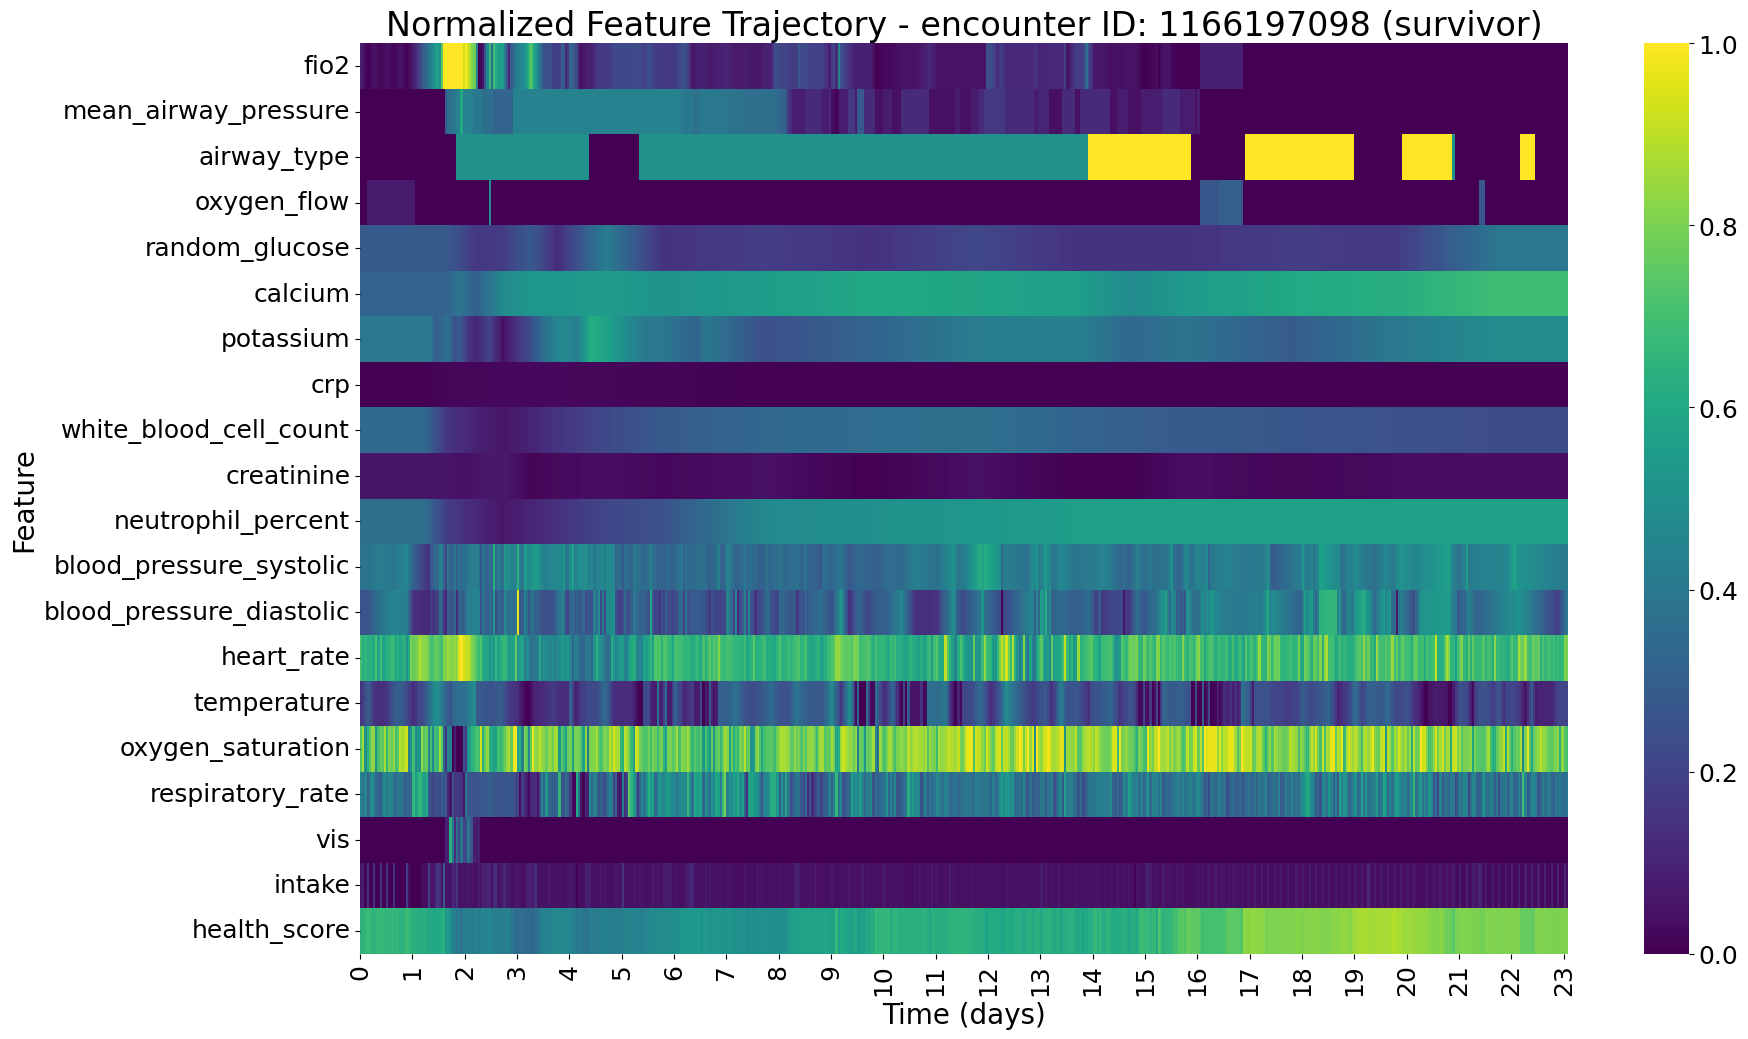

Using example encounter ID: 1166197537
Encounter ID 1166197537 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1166197537_survivor.png


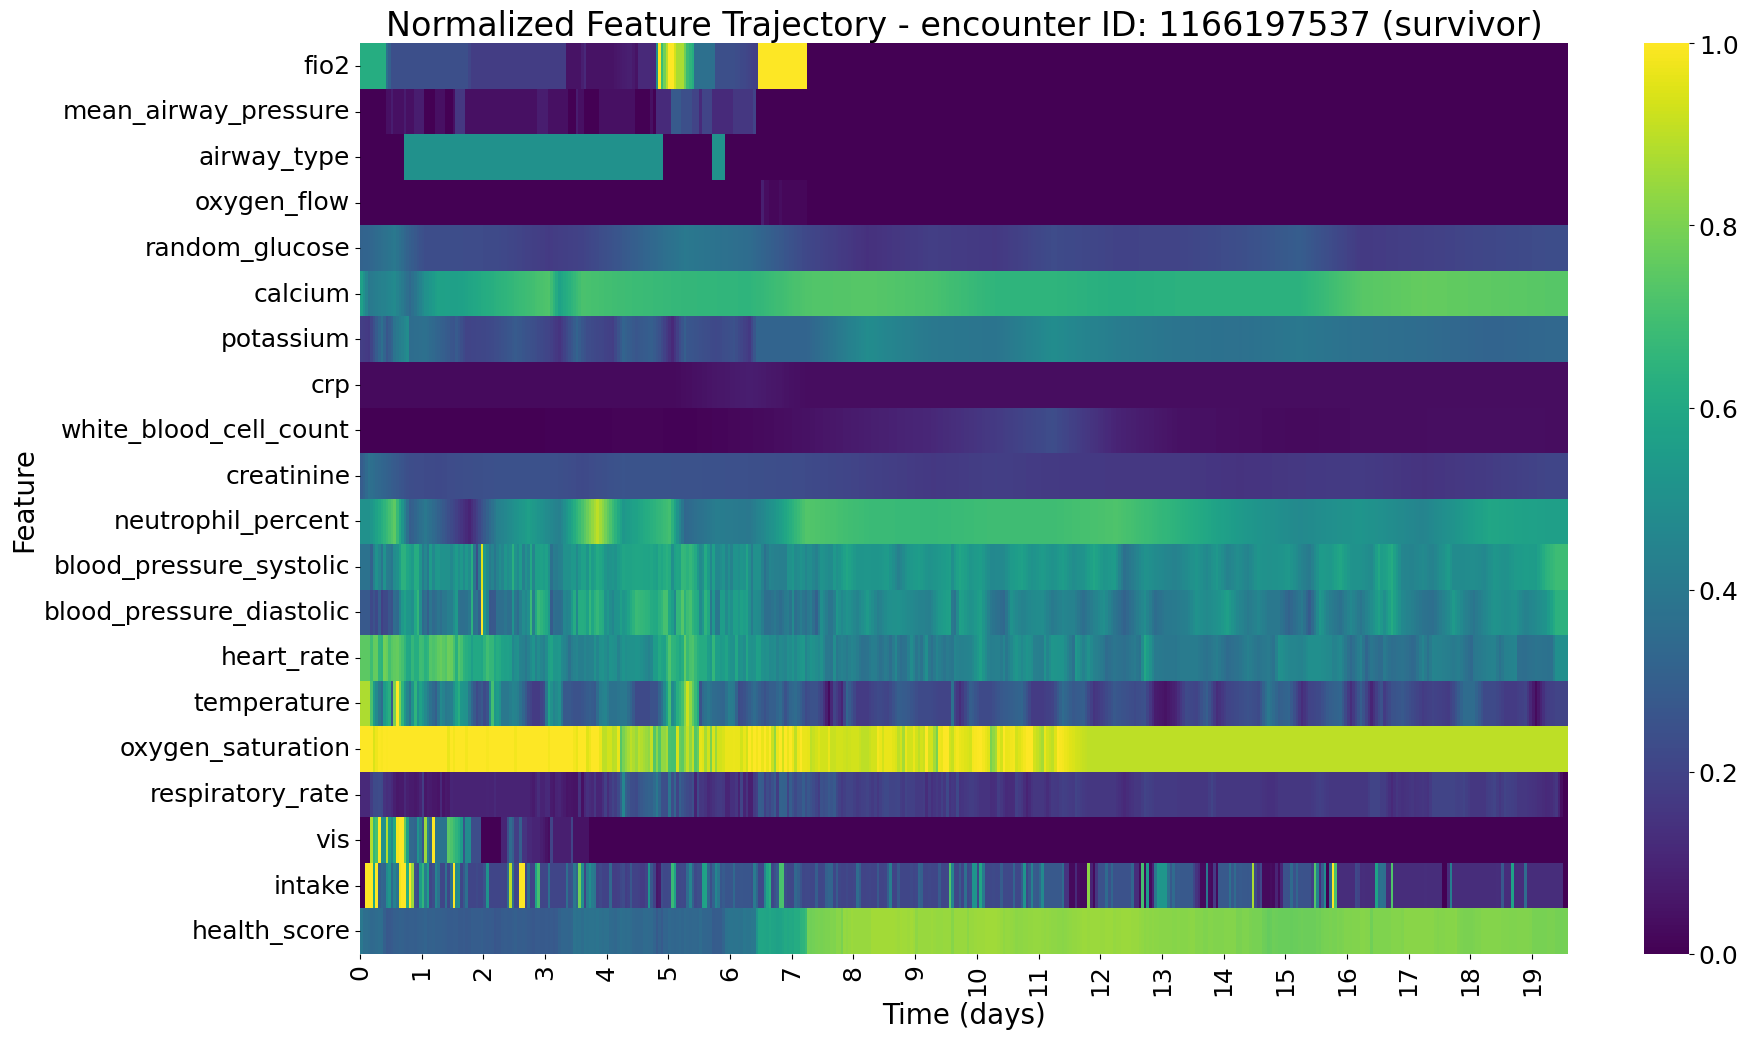

Using example encounter ID: 1166213245
Encounter ID 1166213245 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1166213245_survivor.png


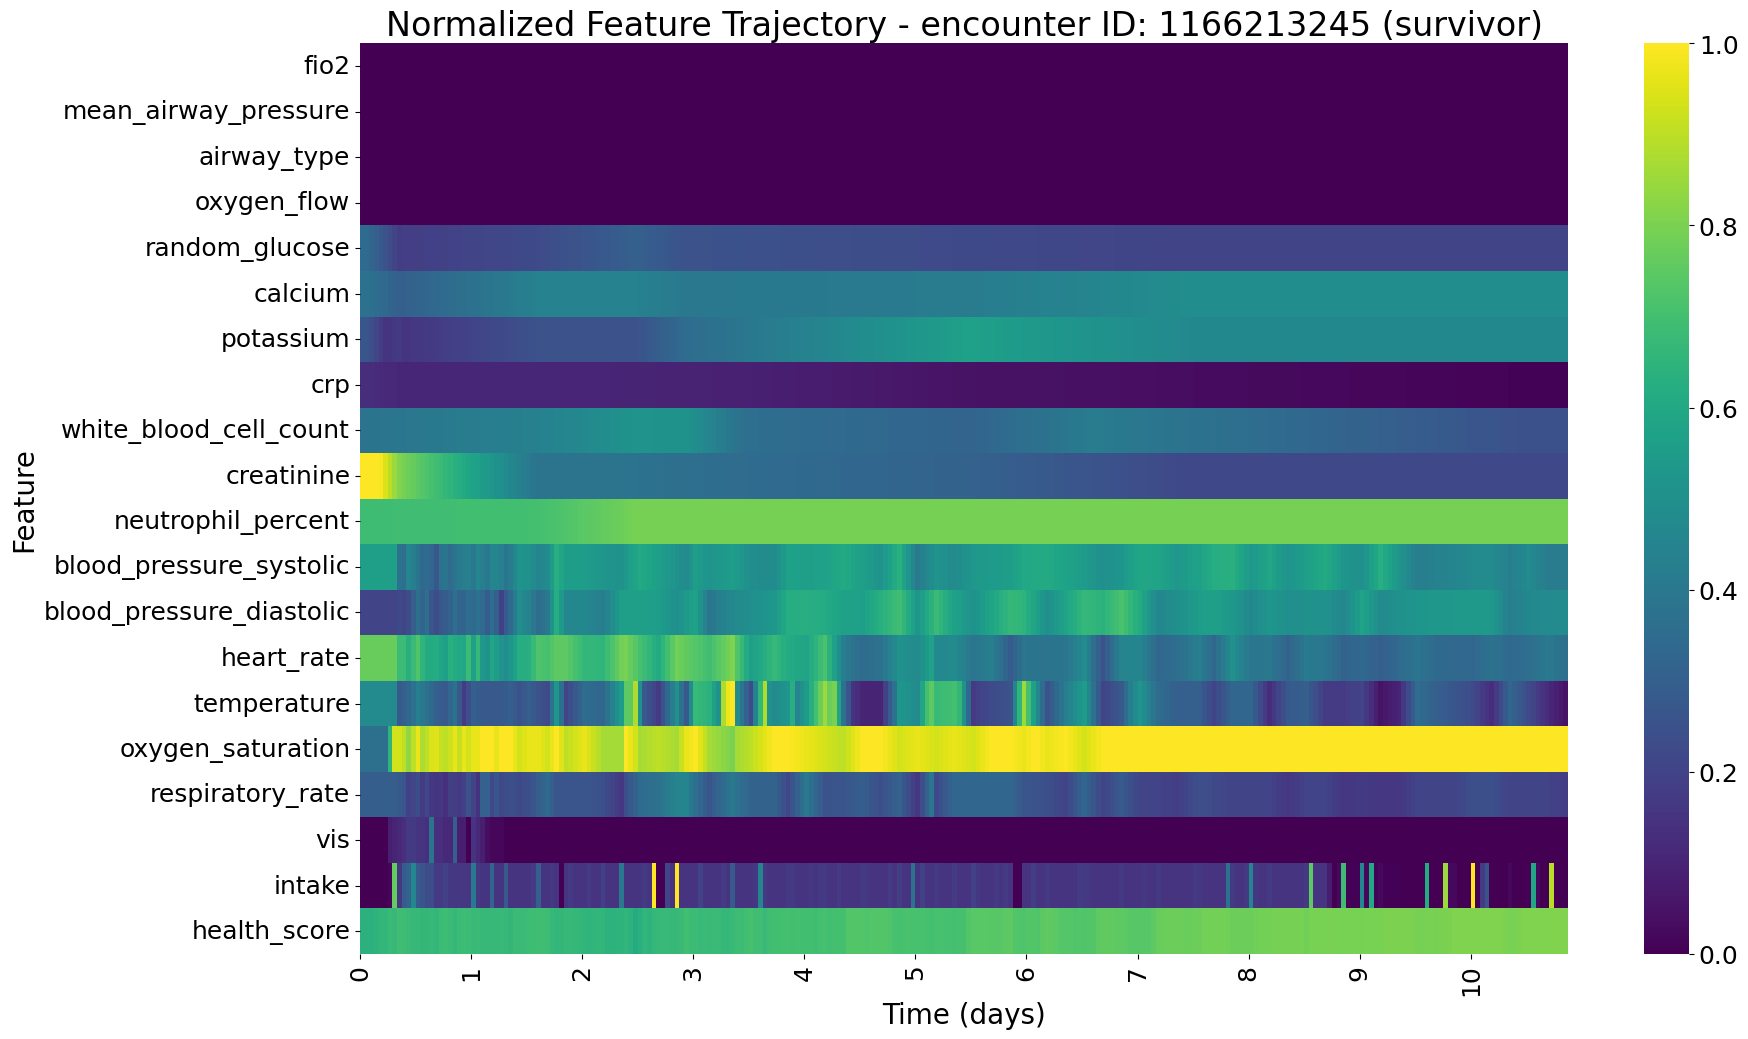

Using example encounter ID: 1166218428
Encounter ID 1166218428 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1166218428_survivor.png


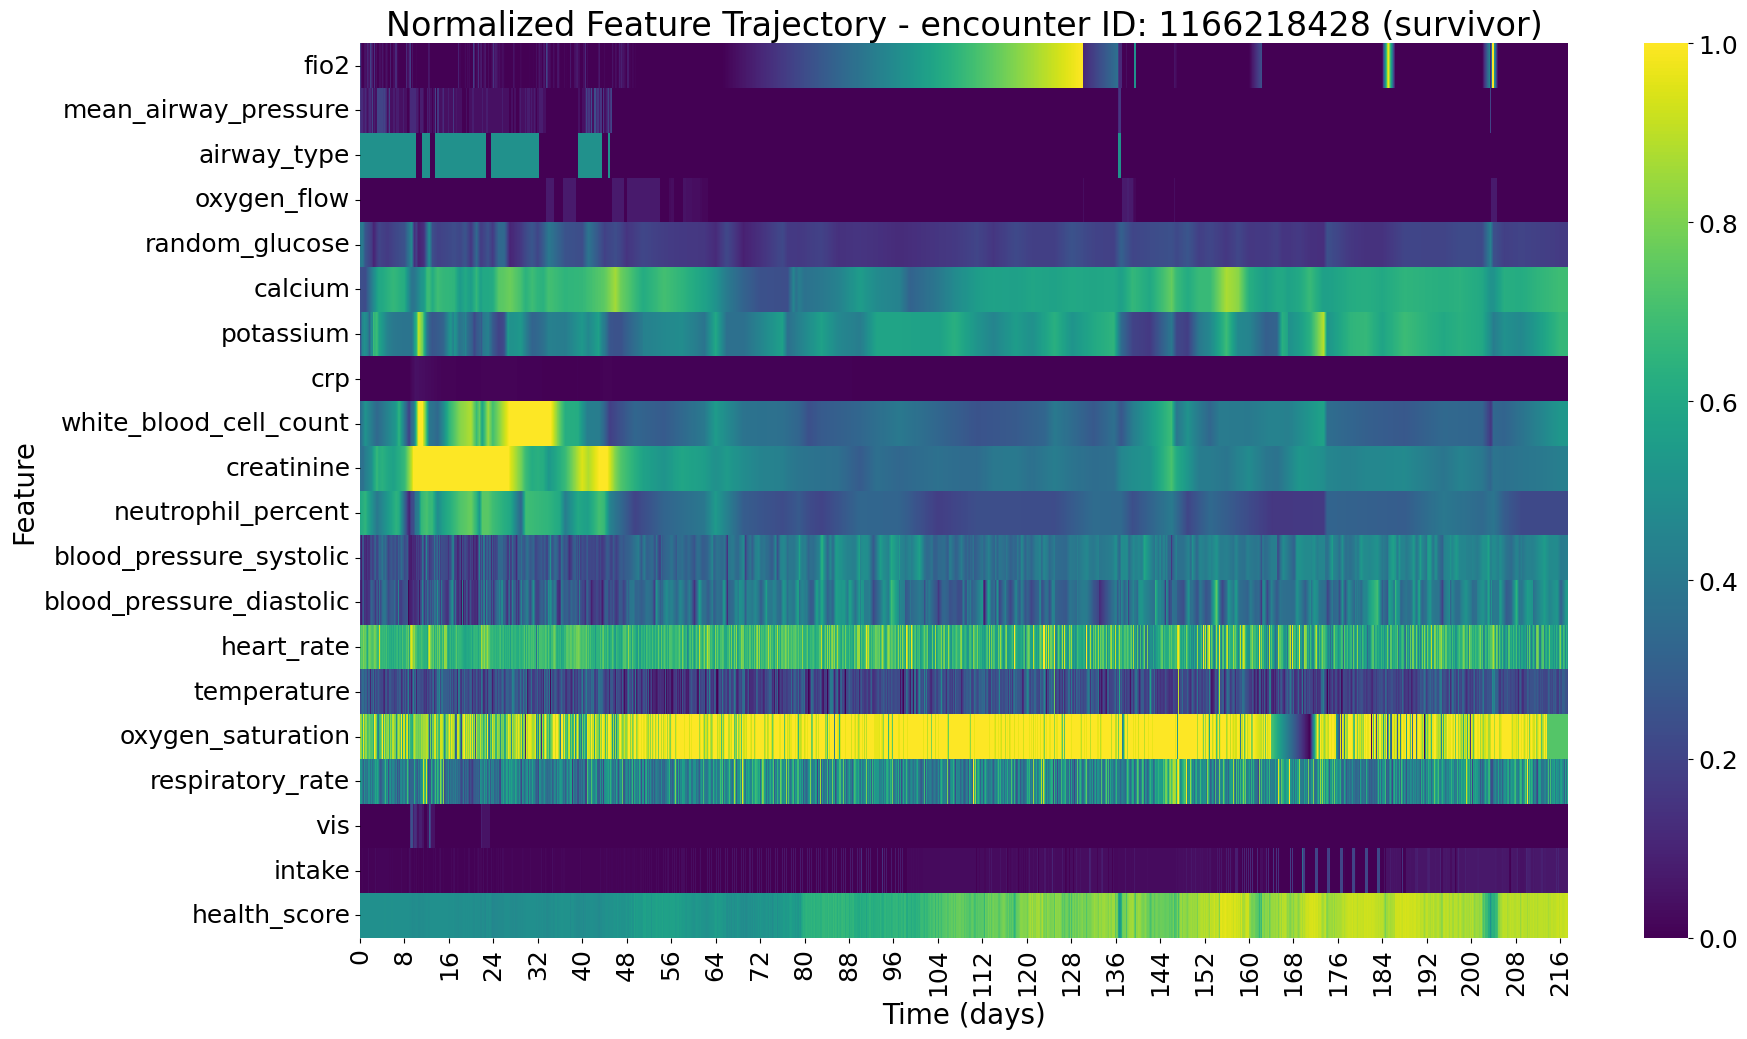

Using example encounter ID: 1166237657
Encounter ID 1166237657 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1166237657_survivor.png


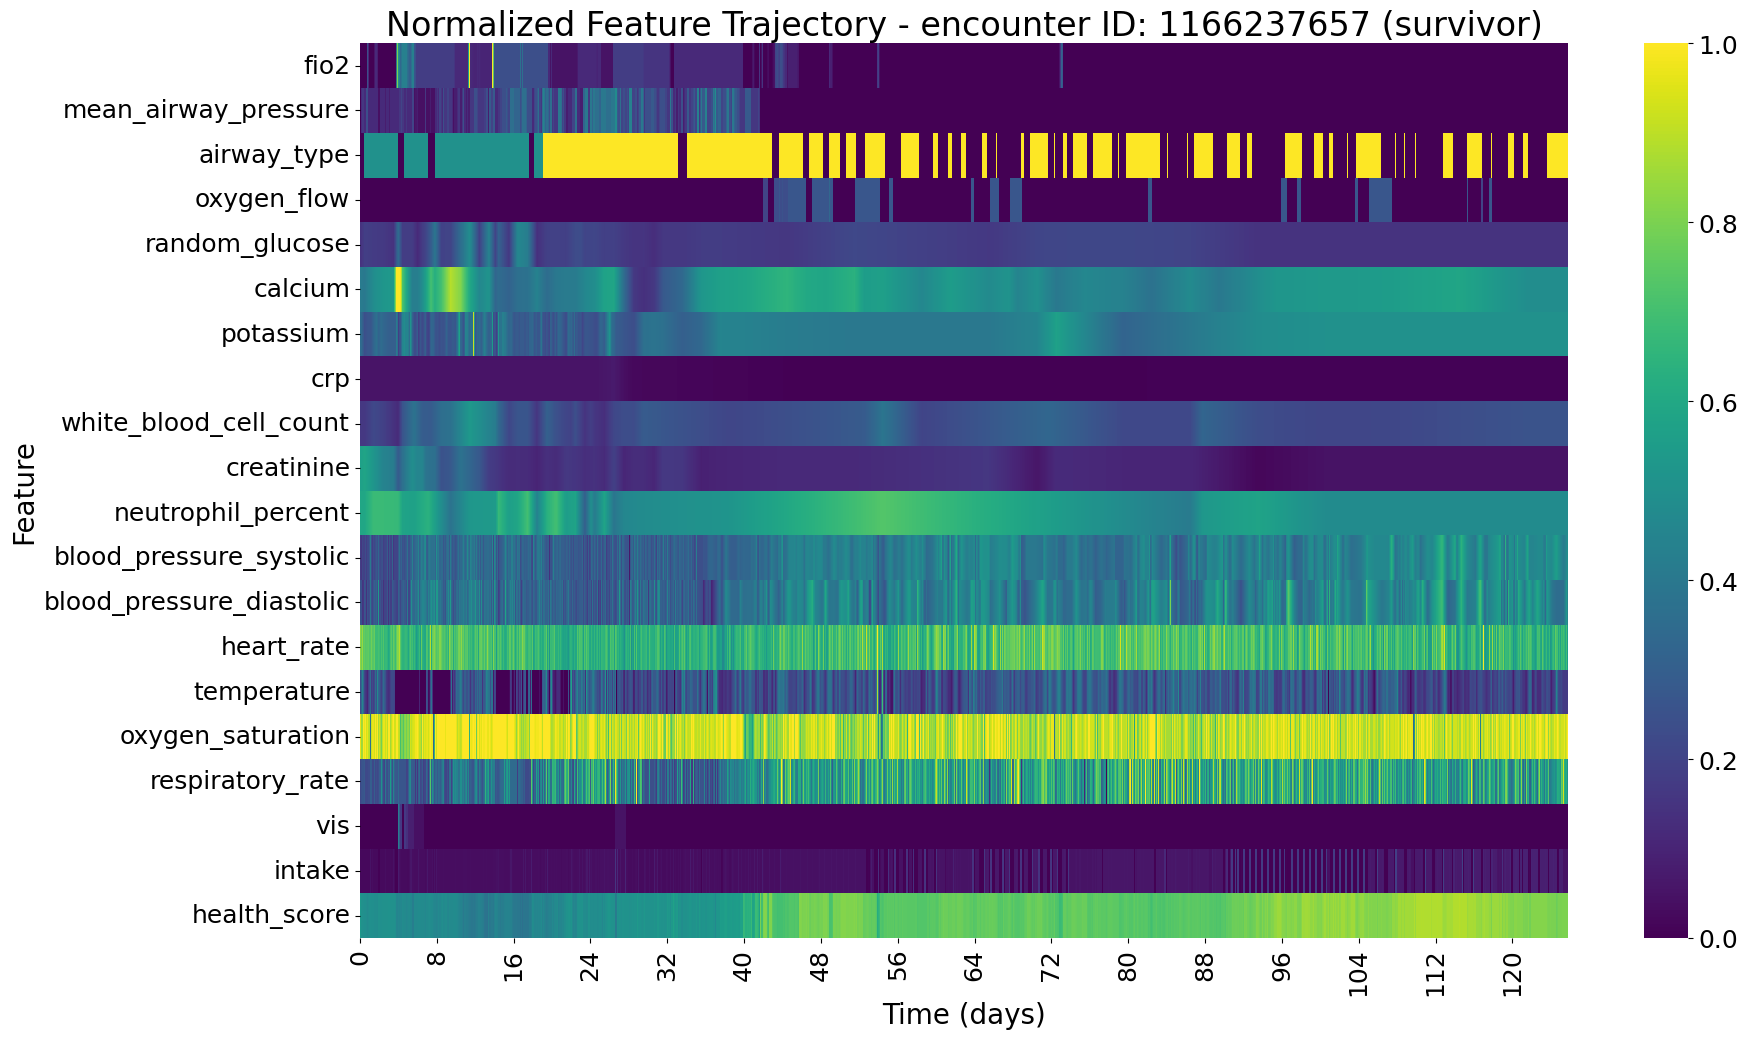

Using example encounter ID: 1166259717
Encounter ID 1166259717 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1166259717_survivor.png


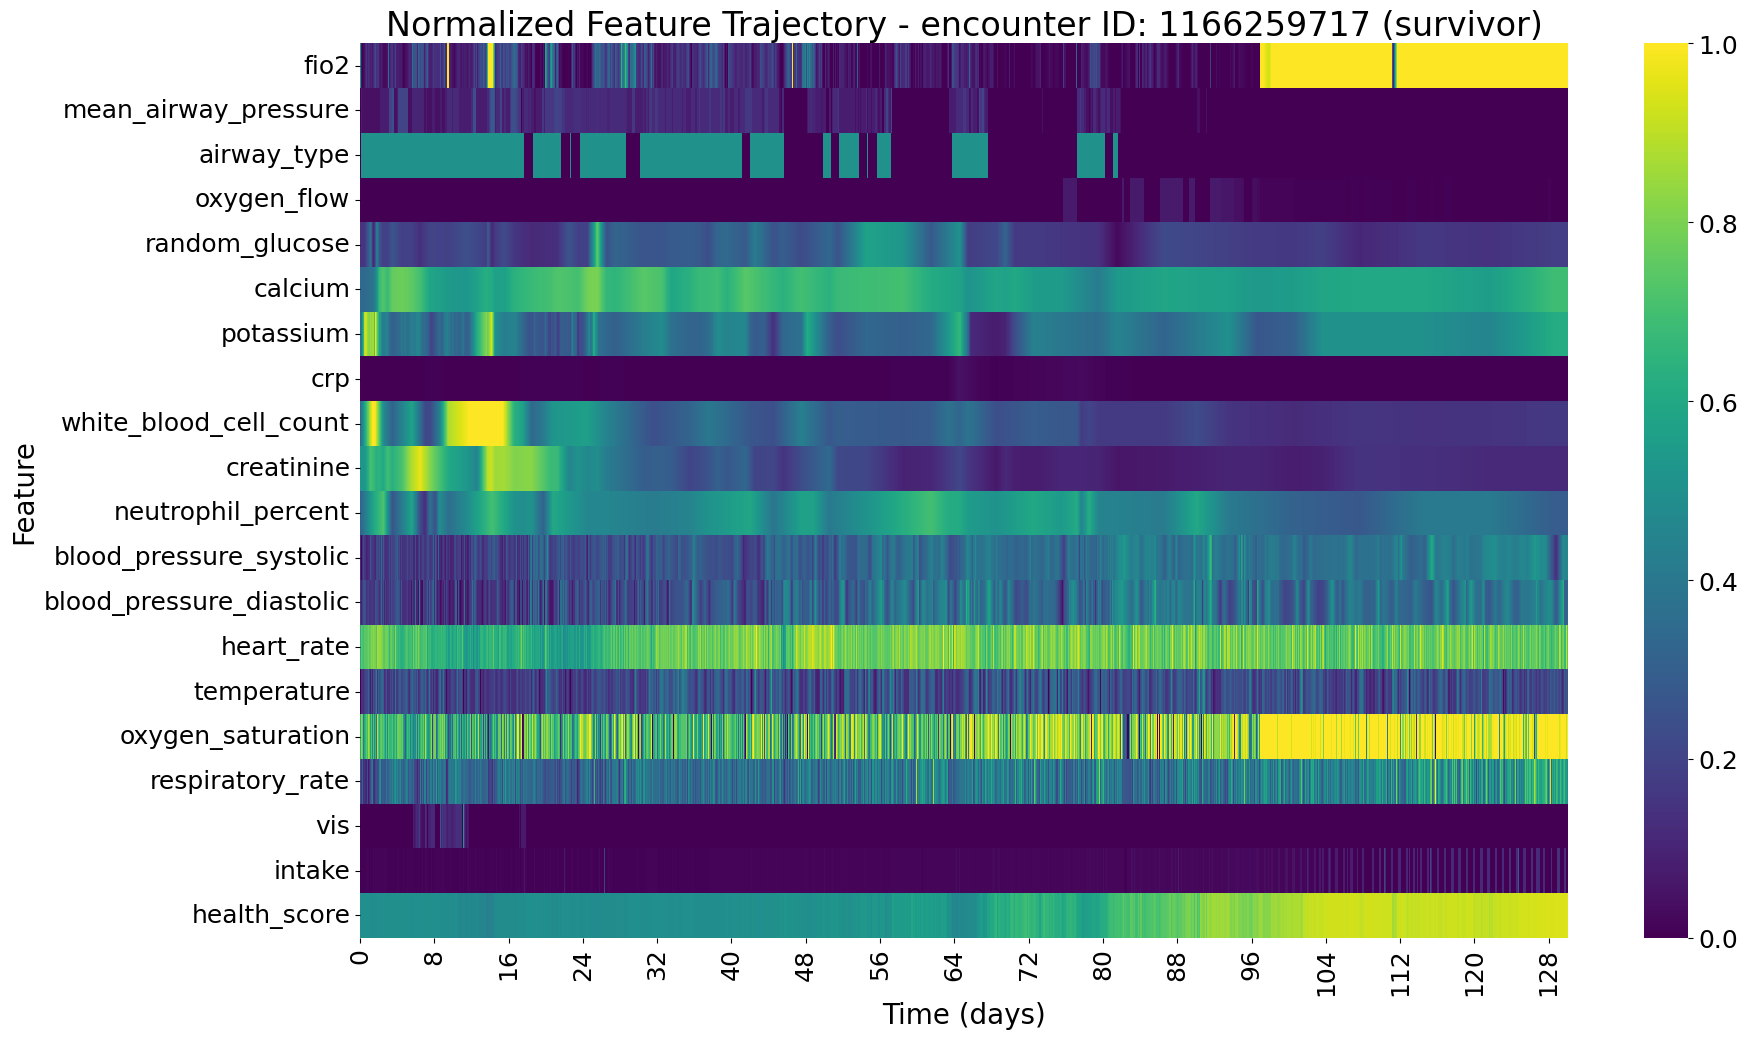

Using example encounter ID: 1166264194
Encounter ID 1166264194 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/health_score_trajectories/encounter_id_1166264194_survivor.png


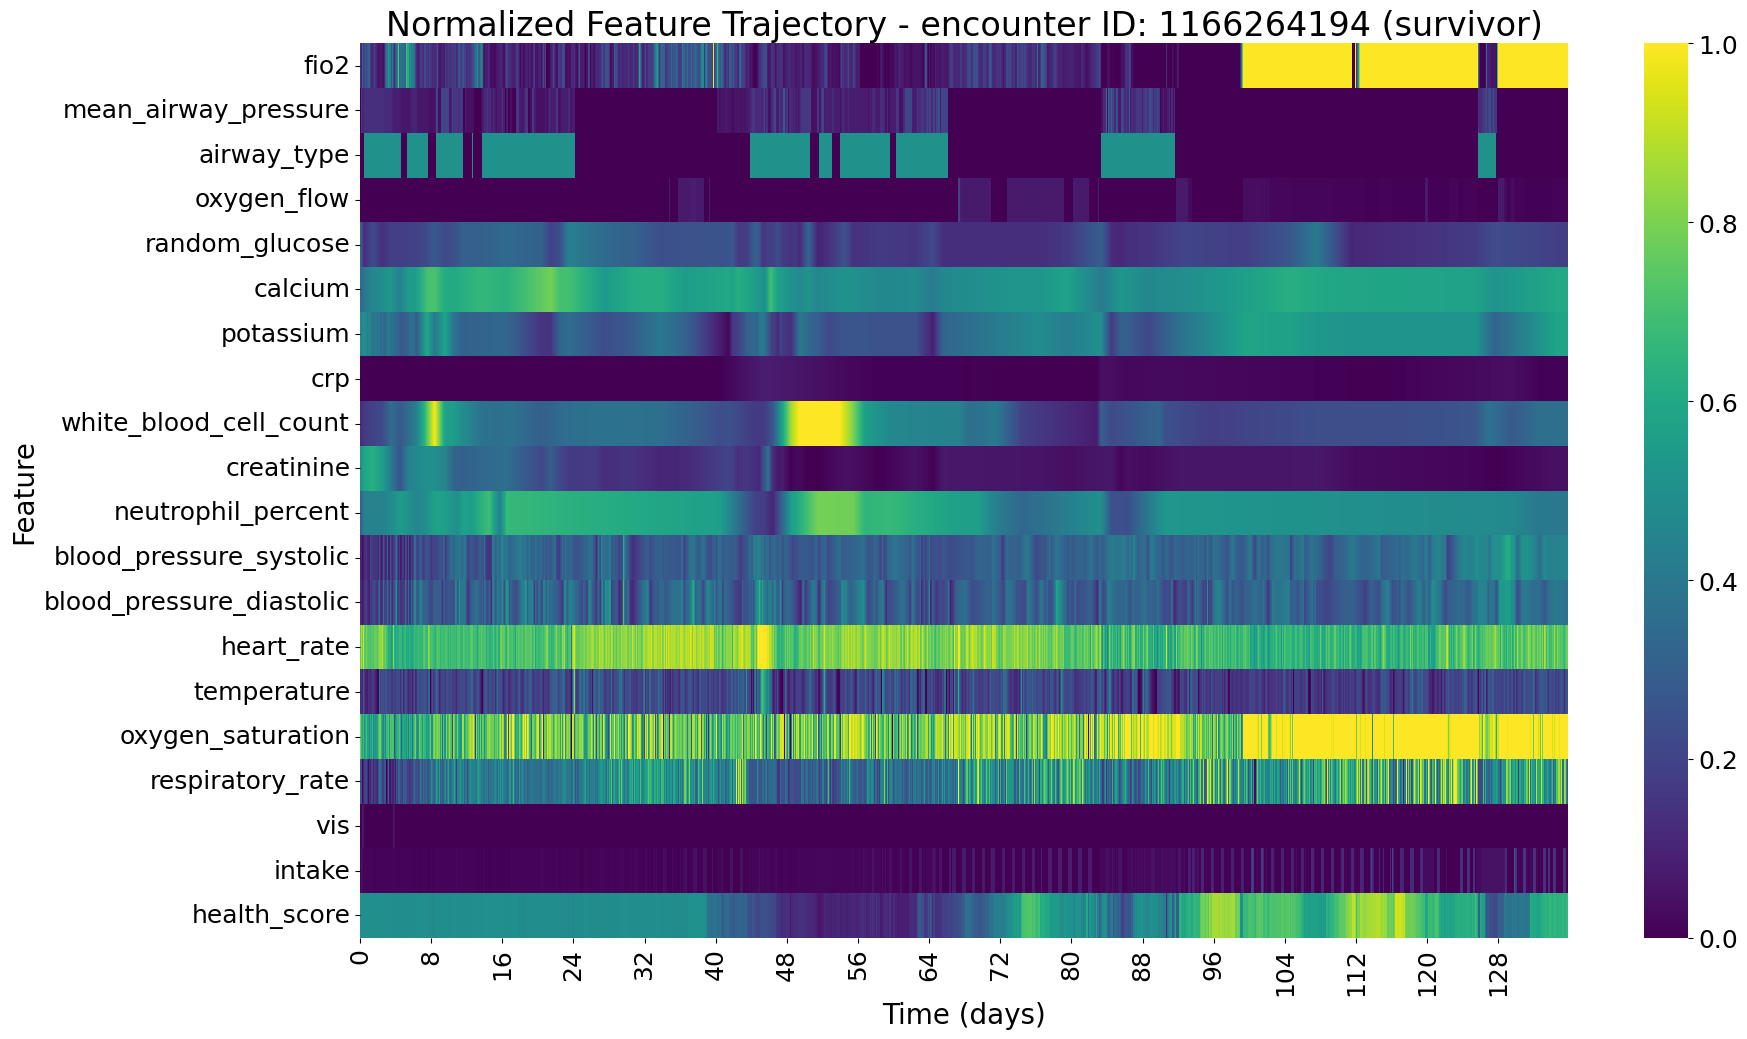

In [144]:
# plot 20 survivor encounters with non-zero VIS
survive_encounter_id = 0
for _ in range(20):
    encounter_id = survivor_ids[survive_encounter_id]
    plot_encounter_heatmap(training_data, non_survivor_ids, encounter_id, plot_dir=plot_dir)
    survive_encounter_id += 1

Using example encounter ID: 1165293630
Encounter ID 1165293630 is a non-survivor.


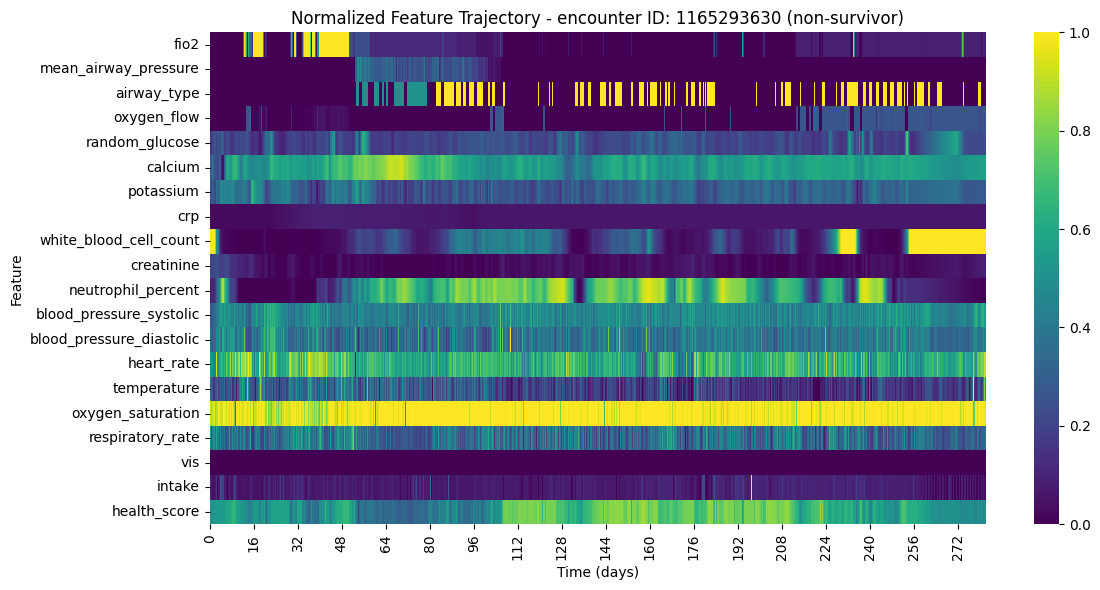

Using example encounter ID: 1165785967
Encounter ID 1165785967 is a non-survivor.


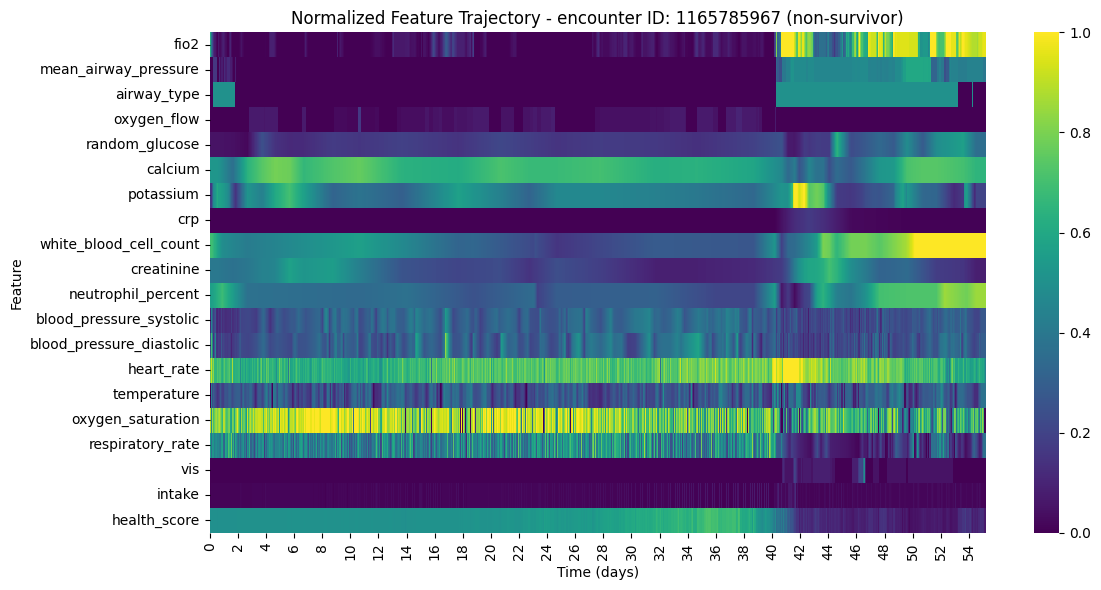

Using example encounter ID: 1165848043
Encounter ID 1165848043 is a non-survivor.


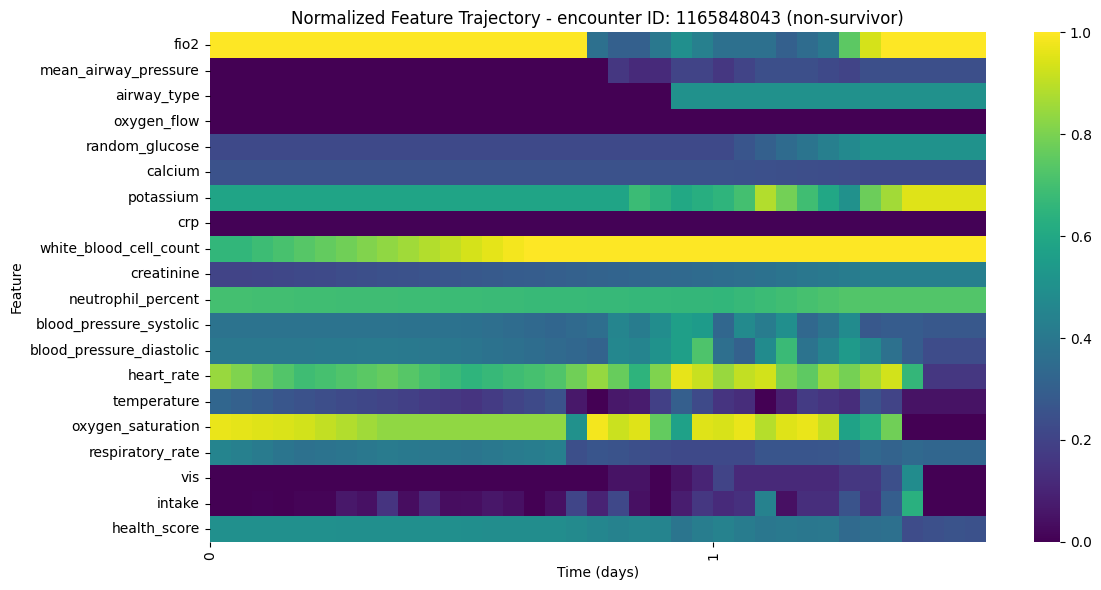

Using example encounter ID: 1165852978
Encounter ID 1165852978 is a non-survivor.


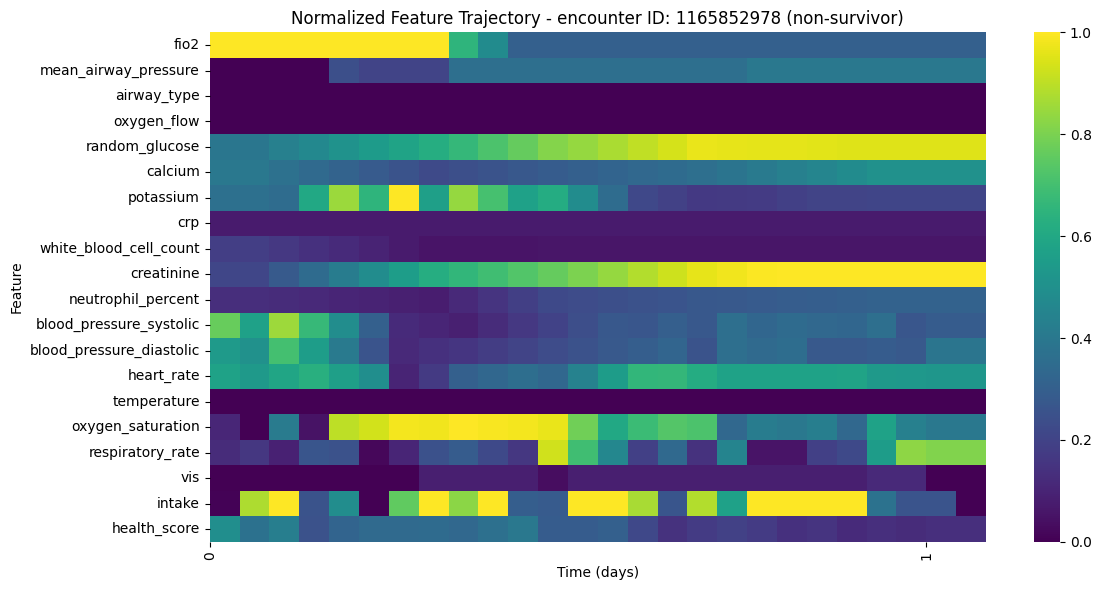

Using example encounter ID: 1166255640
Encounter ID 1166255640 is a non-survivor.


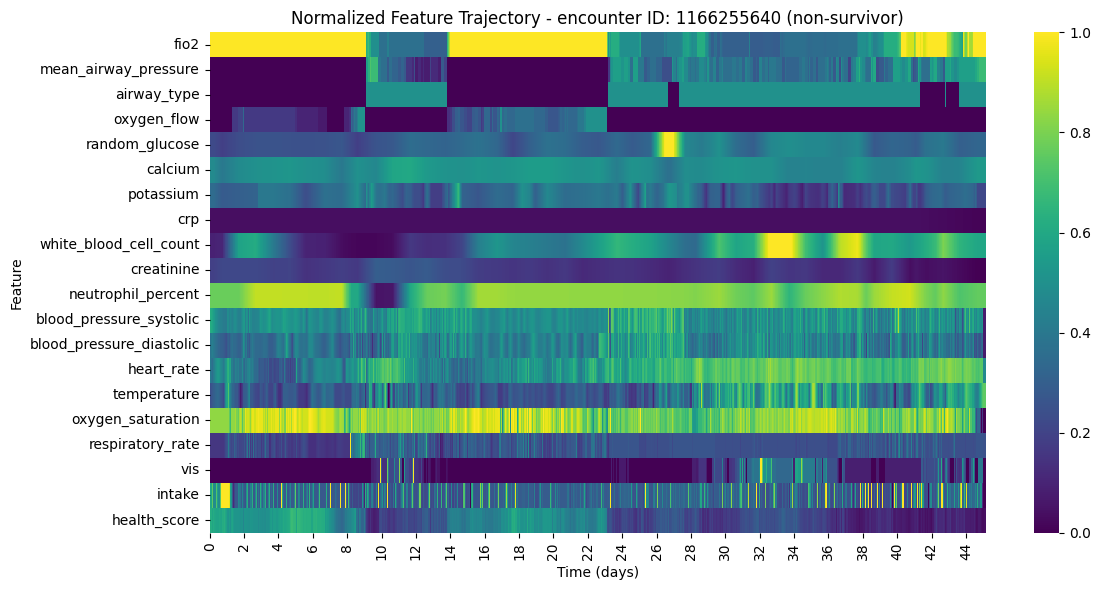

Using example encounter ID: 1166529327
Encounter ID 1166529327 is a non-survivor.


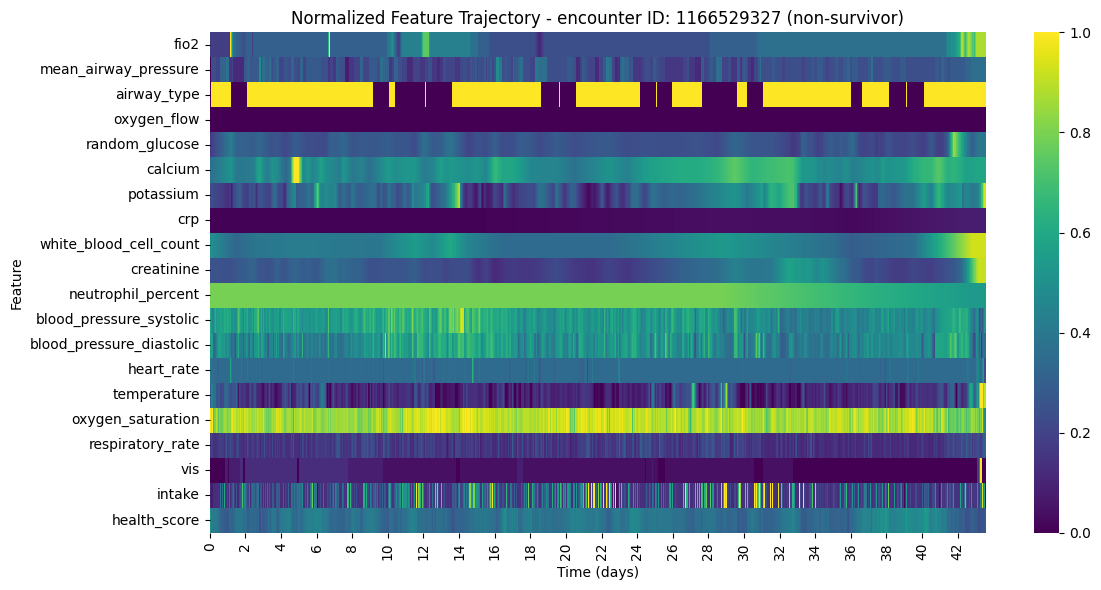

Using example encounter ID: 1166747967
Encounter ID 1166747967 is a non-survivor.


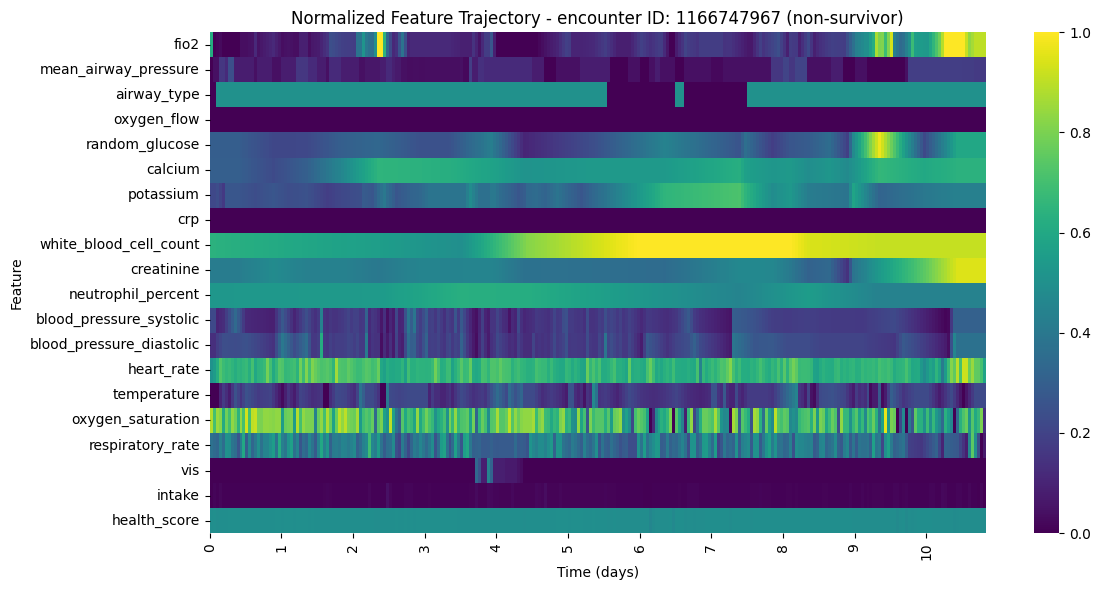

Using example encounter ID: 1166923550
Encounter ID 1166923550 is a non-survivor.


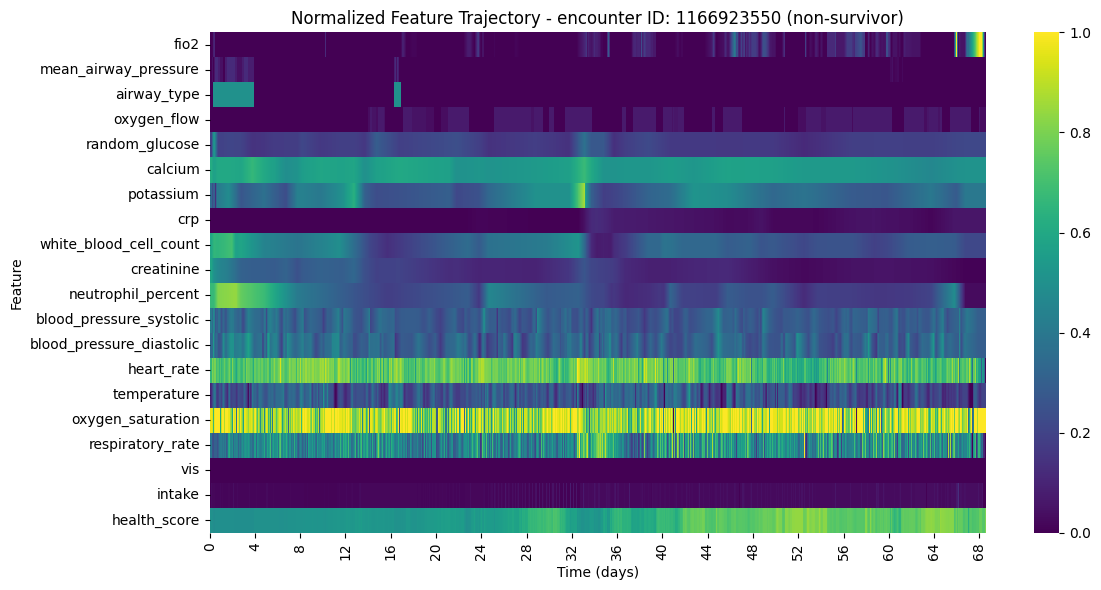

Using example encounter ID: 1166950914
Encounter ID 1166950914 is a non-survivor.


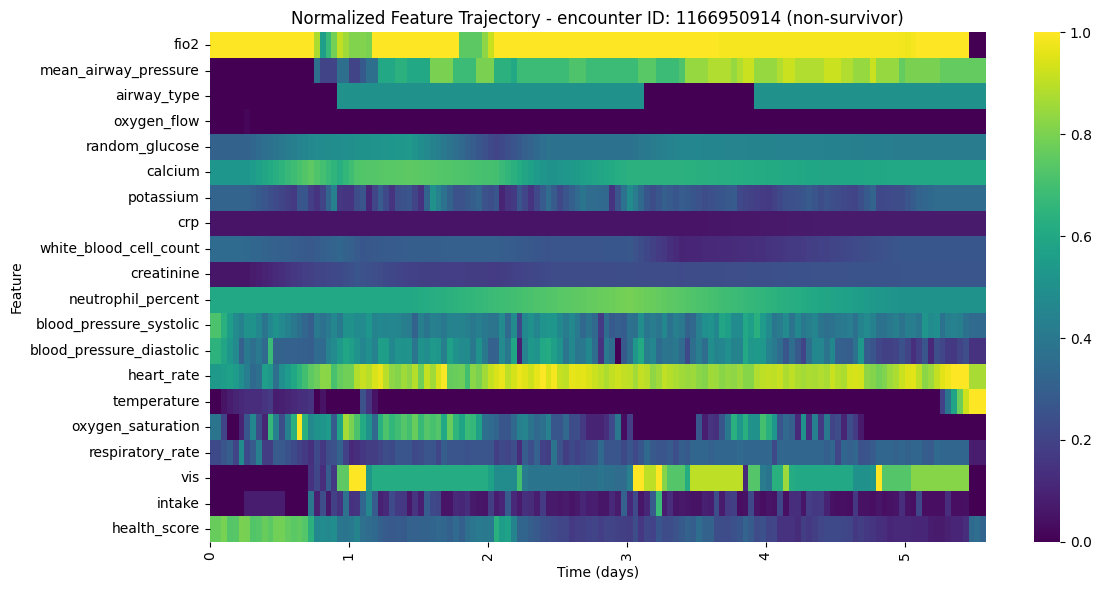

Using example encounter ID: 1167172587
Encounter ID 1167172587 is a non-survivor.


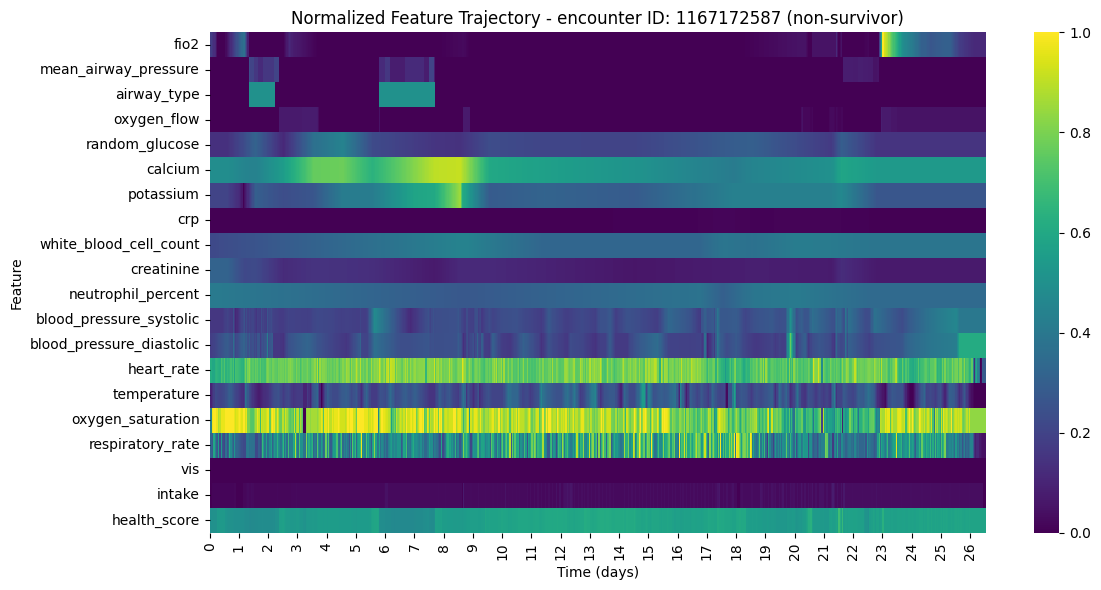

Using example encounter ID: 1167261952
Encounter ID 1167261952 is a non-survivor.


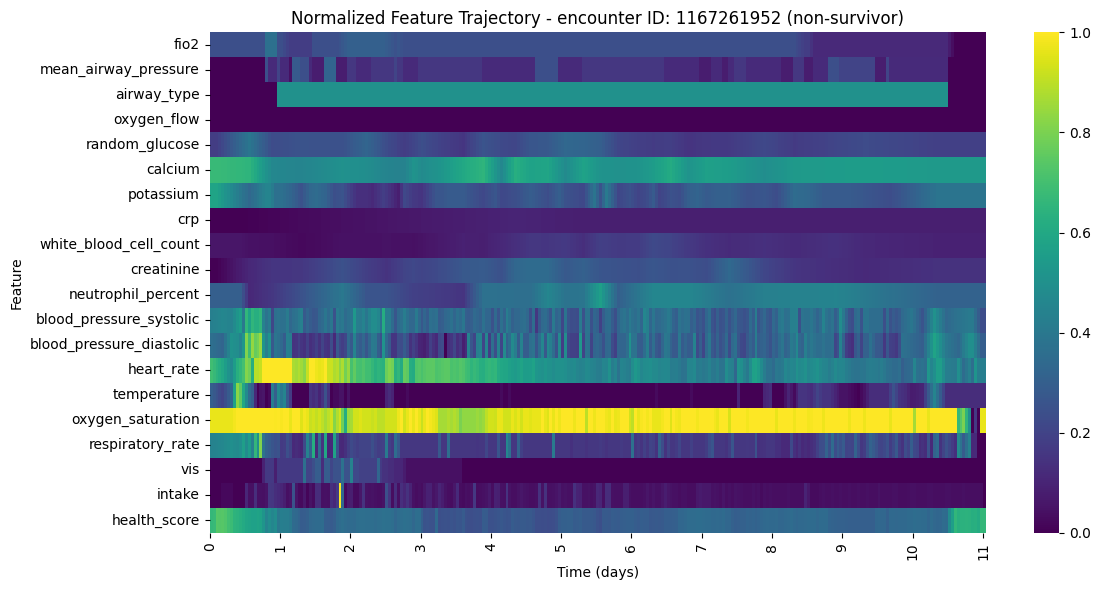

Using example encounter ID: 1167393205
Encounter ID 1167393205 is a non-survivor.


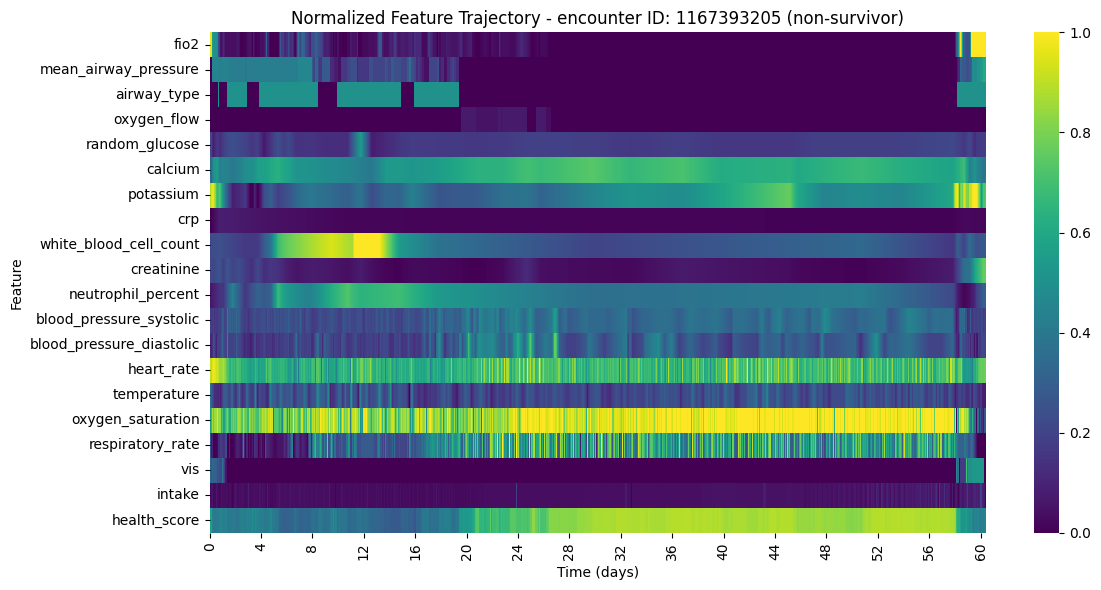

Using example encounter ID: 1167393686
Encounter ID 1167393686 is a non-survivor.


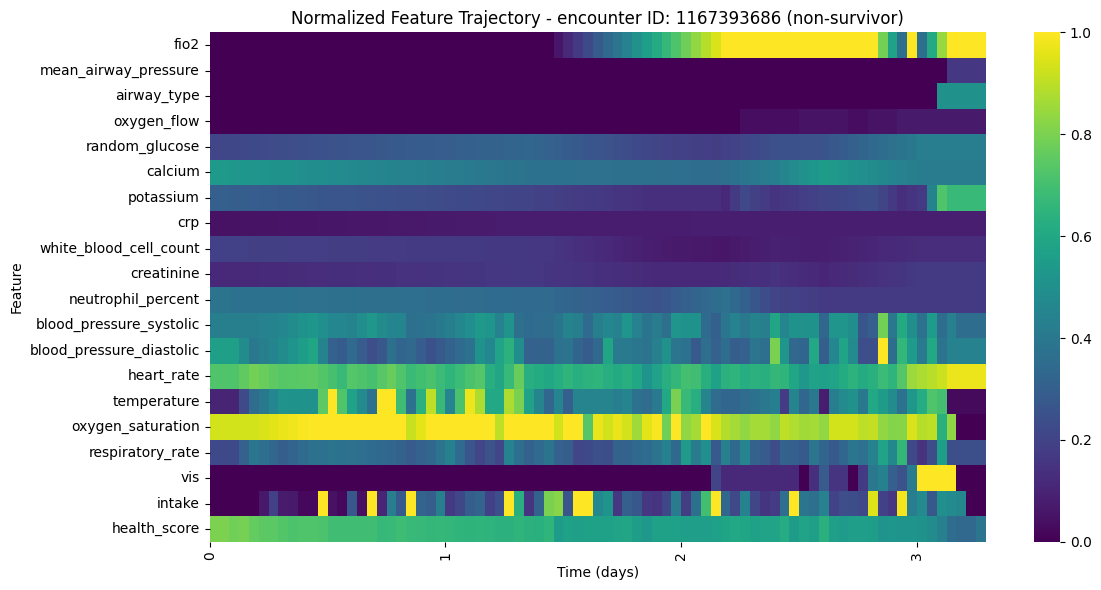

Using example encounter ID: 1167468715
Encounter ID 1167468715 is a non-survivor.


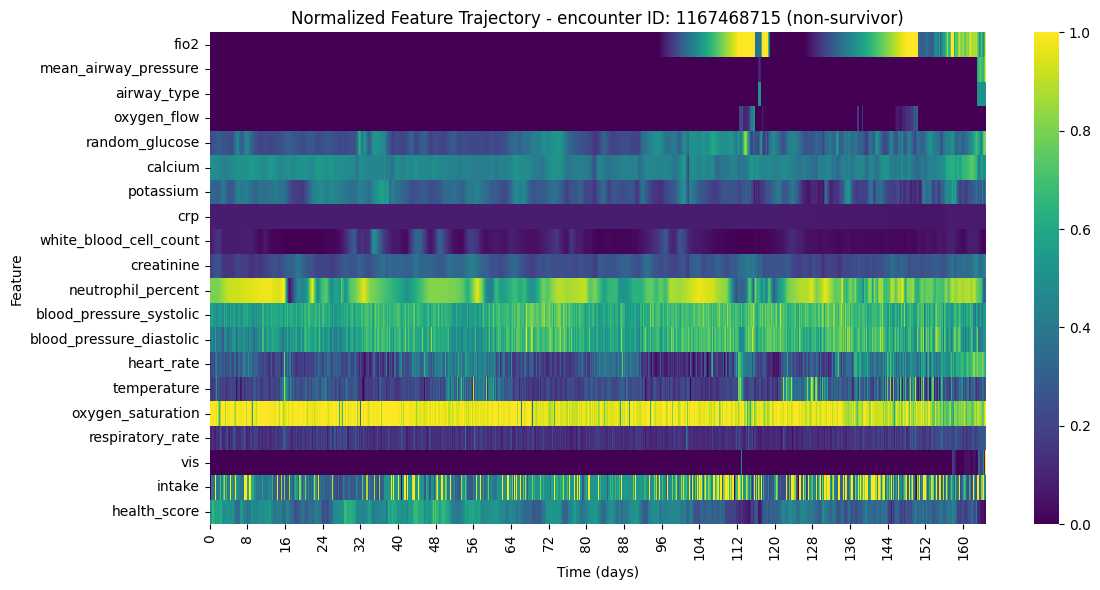

Using example encounter ID: 1167556995
Encounter ID 1167556995 is a non-survivor.


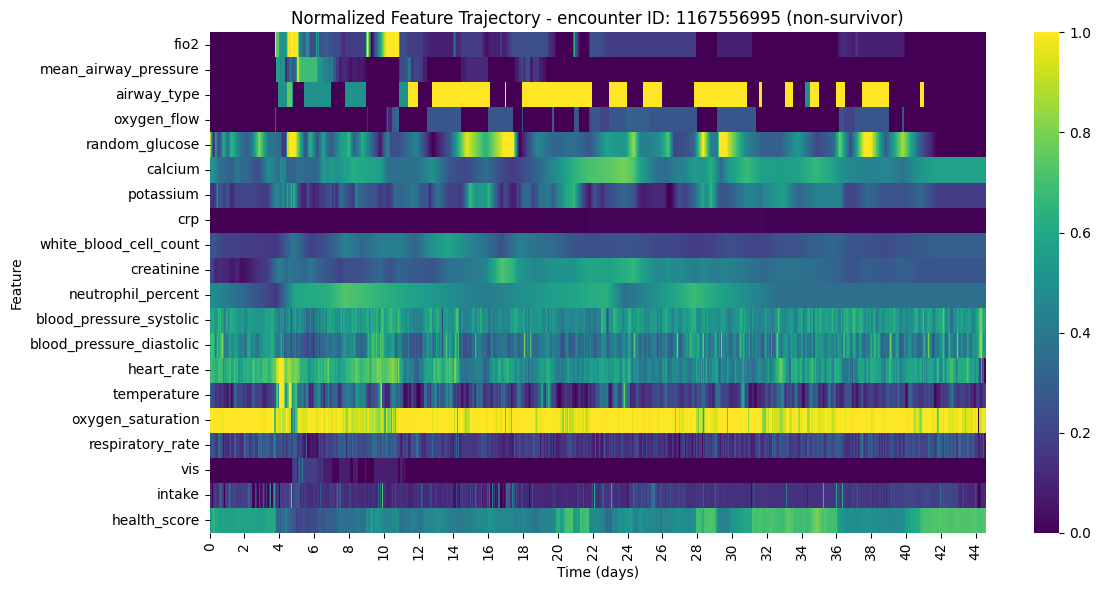

Using example encounter ID: 1167607731
Encounter ID 1167607731 is a non-survivor.


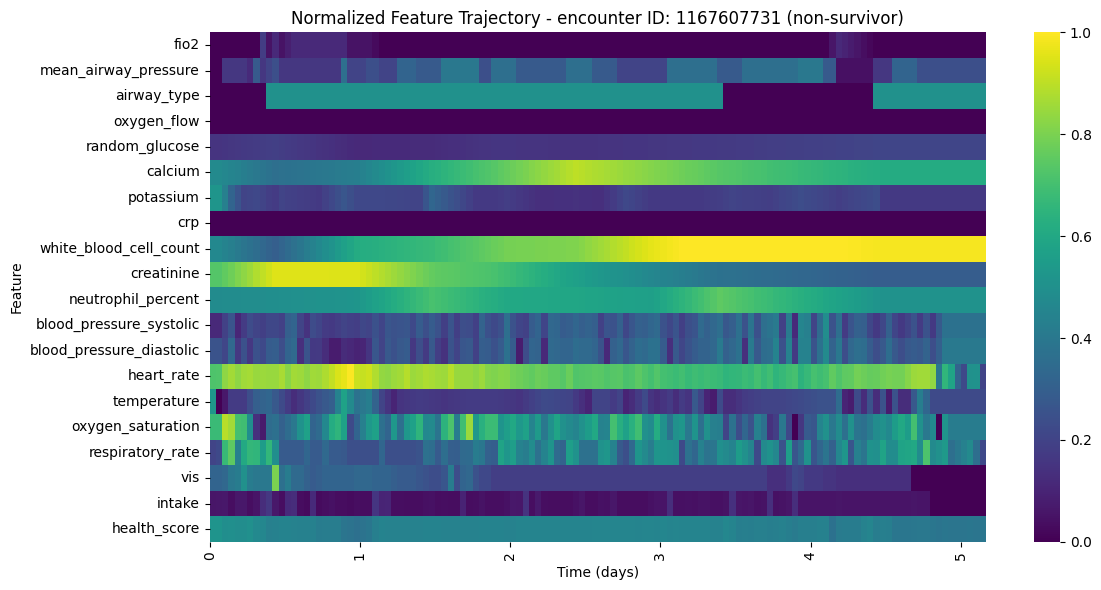

Using example encounter ID: 1167620748
Encounter ID 1167620748 is a non-survivor.


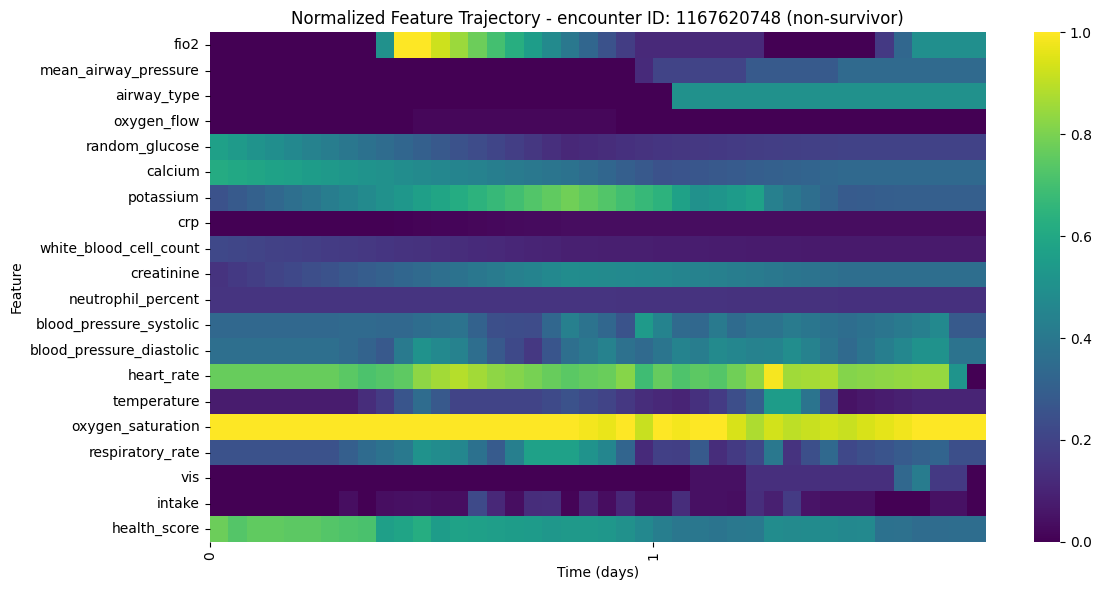

Using example encounter ID: 1167641295
Encounter ID 1167641295 is a non-survivor.


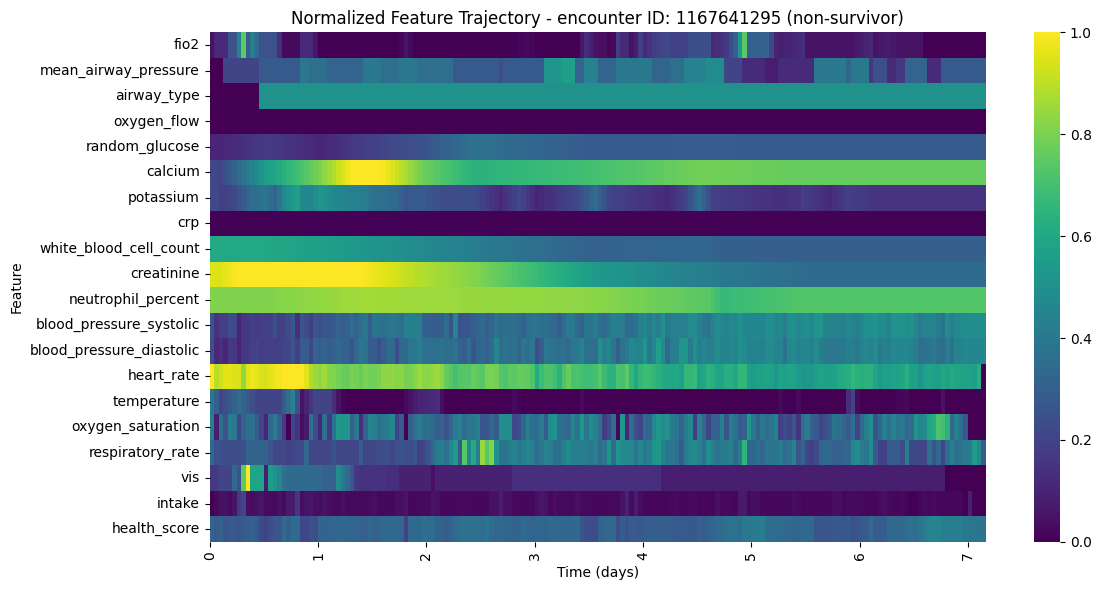

Using example encounter ID: 1167685427
Encounter ID 1167685427 is a non-survivor.


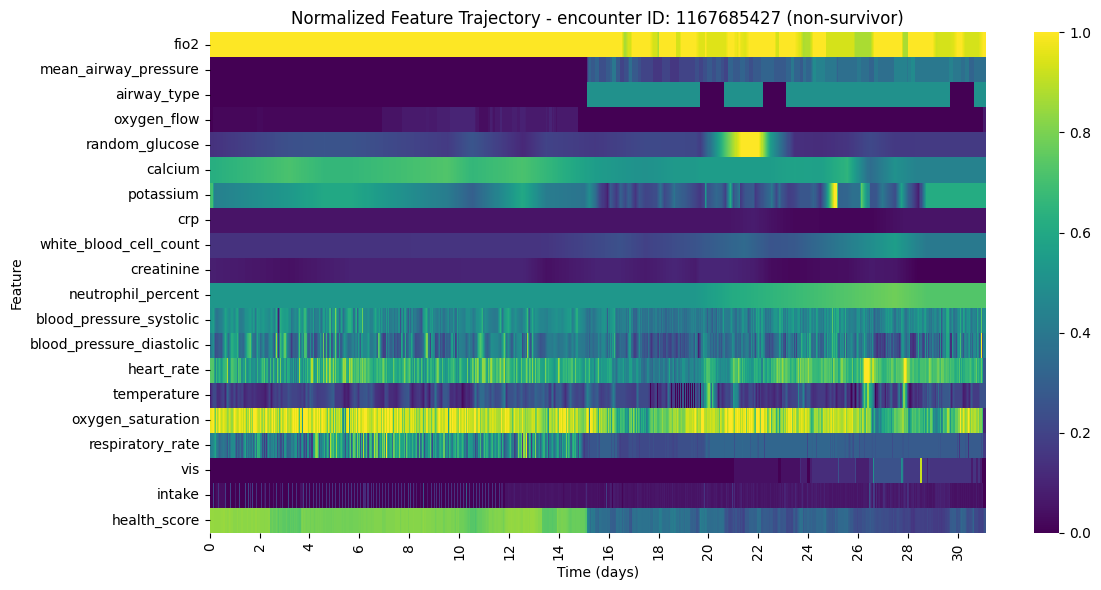

Using example encounter ID: 1167713317
Encounter ID 1167713317 is a non-survivor.


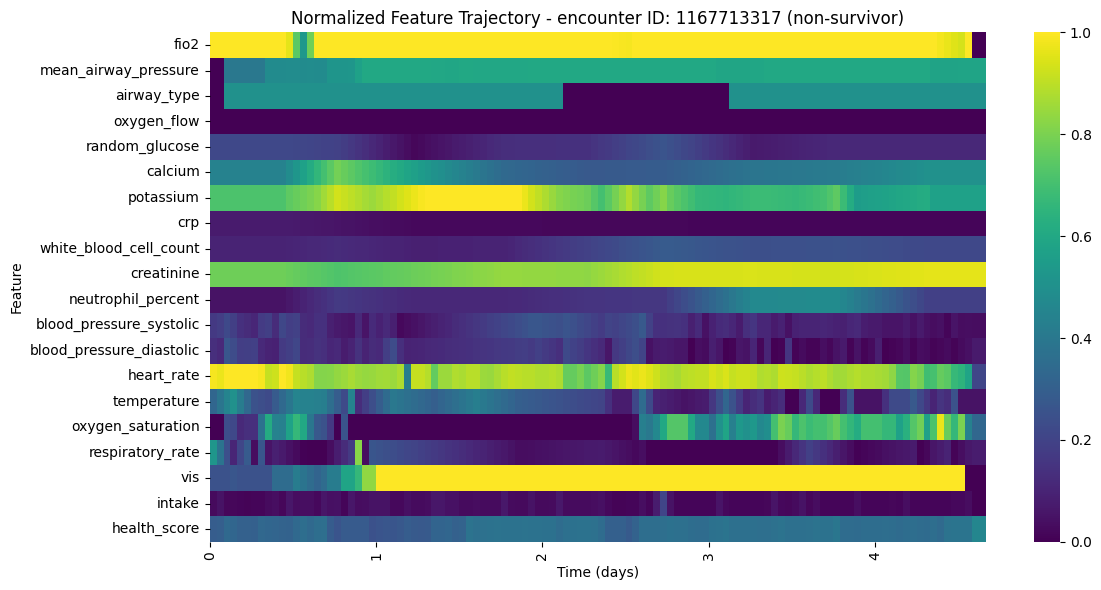

In [133]:
# plot 20 non-survivor encounters 
non_survive_encounter_id = 0
for _ in range(20):
    encounter_id = non_survivor_ids[non_survive_encounter_id]
    plot_encounter_heatmap(training_data, non_survivor_ids, encounter_id)
    non_survive_encounter_id += 1

In [ ]:
# plot 20 non-survivor encounters
non_survive_encounter_id = 0
for _ in range(20):
    encounter_id = non_survivor_ids[non_survive_encounter_id]
    plot_encounter_heatmap(training_data, predictions_df, non_survivor_ids, encounter_id)
    non_survive_encounter_id += 1

Using example encounter ID: 1165293630
Encounter ID 1165293630 is a non-survivor.


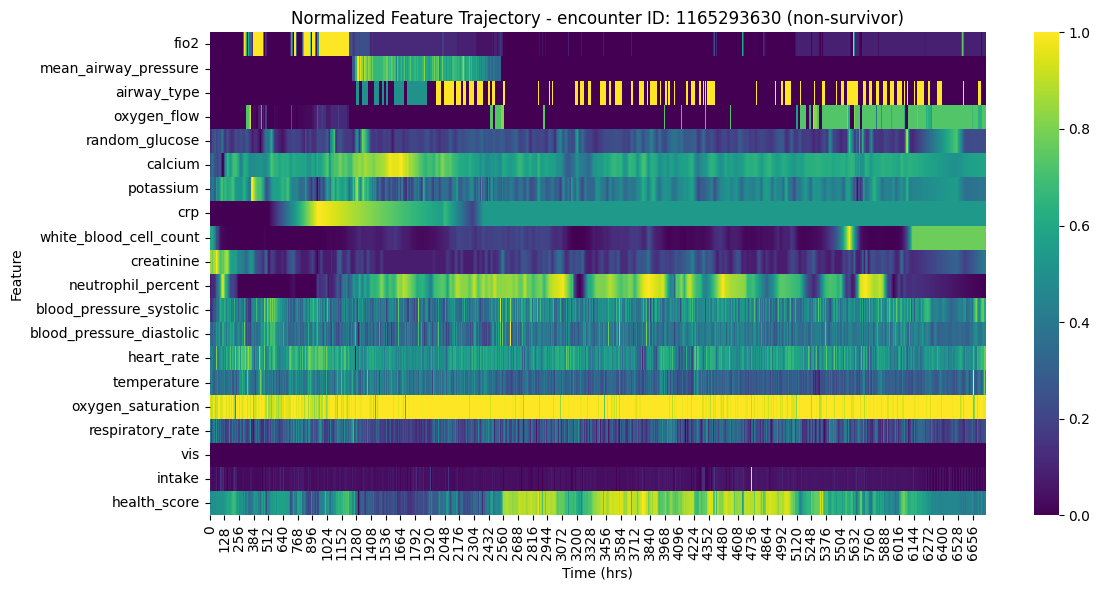

In [47]:
non_survive_encounter_id = 0
encounter_id = non_survivor_ids[non_survive_encounter_id]
example_training_traj = plot_encounter_heatmap(training_data, predictions_df, non_survivor_ids, encounter_id)
non_survive_encounter_id += 1

In [48]:
non_survive_encounter_id = 0
encounter_id = non_survivor_ids[non_survive_encounter_id]
example_training_traj = plot_encounter_heatmap(training_data, predictions_df, non_survivor_ids, encounter_id)
non_survive_encounter_id += 1

np.float64(1.0)

In [18]:
encounter_traj

,fio2,mean_airway_pressure,airway_type,oxygen_flow,random_glucose,calcium,potassium,crp,white_blood_cell_count,creatinine,neutrophil_percent,blood_pressure_systolic,blood_pressure_diastolic,heart_rate,temperature,oxygen_saturation,respiratory_rate,vis,health_score
10936,0.21,0.0,0.0,0.0,135.0,8.1,4.100,0.020000,5.900000,0.63,23.000000,23.0,19.0,122.0,34.30,89.0,36.0,0.0,1.000093
10937,0.25,0.0,0.0,0.0,135.0,8.1,4.100,0.020000,5.900000,0.63,23.000000,23.0,19.0,122.0,34.30,89.0,36.0,0.0,0.998889
10938,0.29,10.0,0.0,0.0,135.0,8.1,4.100,0.030833,5.883333,0.63,24.666667,23.0,19.0,140.0,35.35,87.5,28.0,0.0,0.998305
10939,0.29,9.0,0.0,0.0,135.0,8.1,3.900,0.041667,5.866667,0.63,26.333333,23.0,19.0,134.0,36.40,92.0,38.0,0.0,0.997815
10940,0.25,9.0,0.0,0.0,135.0,8.1,4.015,0.052500,5.850000,0.63,28.000000,25.0,16.0,148.0,36.50,93.0,40.0,5.0,0.998212
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13961,1.00,0.0,0.0,0.1,93.0,10.5,4.400,1.050000,10.900000,0.26,30.000000,76.0,56.0,143.5,36.90,97.0,57.5,0.0,1.931085
13962,1.00,0.0,0.0,0.1,93.0,10.5,4.400,1.050000,10.900000,0.26,30.000000,76.0,56.0,159.0,36.90,97.0,34.0,0.0,1.930064
13963,1.00,0.0,0.0,0.1,93.0,10.5,4.400,1.050000,10.900000,0.26,30.000000,76.0,56.0,154.0,36.90,97.0,46.0,0.0,1.930845
13964,1.00,0.0,0.0,0.1,93.0,10.5,4.400,1.050000,10.900000,0.26,30.000000,76.0,56.0,154.0,36.90,97.0,46.0,0.0,1.930845


Using example encounter ID: 1165746083


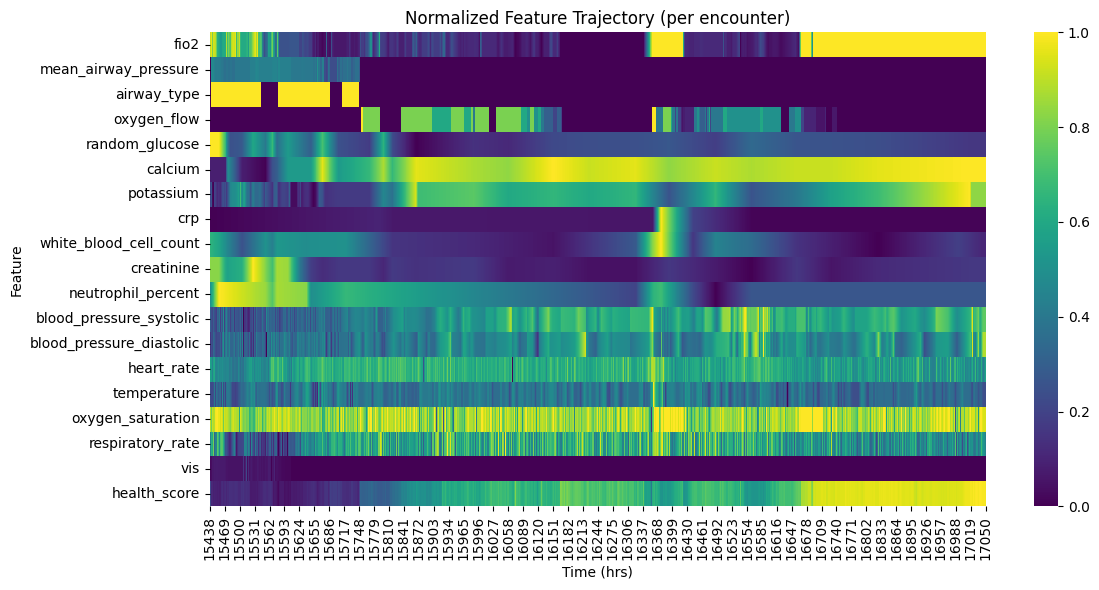

,fio2,mean_airway_pressure,airway_type,oxygen_flow,random_glucose,calcium,potassium,crp,white_blood_cell_count,creatinine,neutrophil_percent,blood_pressure_systolic,blood_pressure_diastolic,heart_rate,temperature,oxygen_saturation,respiratory_rate,vis,health_score
15438,0.9275,0.0,0.0,0.0,232.0,8.2,3.750,0.020000,25.500000,1.04,60.000000,63.0,27.0,153.000000,36.500000,96.555556,48.000000,8.0,0.982561
15439,0.9275,0.0,0.0,0.0,232.0,8.2,3.750,0.020000,25.500000,1.04,60.000000,63.0,27.0,153.000000,36.500000,96.555556,48.000000,8.0,0.981709
15440,0.9700,12.7,1.0,0.0,232.0,8.2,3.825,0.024375,25.411111,1.04,61.222222,67.0,39.0,155.333333,36.466667,89.333333,49.333333,8.0,0.877525
15441,0.9700,14.0,1.0,0.0,232.0,8.2,3.900,0.028750,25.322222,1.04,62.444444,59.0,34.0,150.750000,36.433333,92.500000,66.750000,10.0,0.869072
15442,0.9700,14.0,1.0,0.0,232.0,8.2,3.500,0.033125,25.233333,1.04,63.666667,61.0,40.0,135.333333,36.400000,98.000000,55.000000,13.0,0.869765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17046,1.0000,0.0,0.0,0.0,83.0,10.4,5.900,0.190000,11.300000,0.30,49.000000,106.0,87.0,129.666667,36.500000,98.000000,56.333333,0.0,1.724013
17047,1.0000,0.0,0.0,0.0,83.0,10.4,5.900,0.190000,11.300000,0.30,49.000000,106.0,87.0,133.000000,36.500000,98.000000,57.000000,0.0,1.724013
17048,1.0000,0.0,0.0,0.0,83.0,10.4,5.900,0.190000,11.300000,0.30,49.000000,106.0,87.0,140.333333,36.500000,98.000000,53.666667,0.0,1.724013
17049,1.0000,0.0,0.0,0.0,83.0,10.4,5.900,0.190000,11.300000,0.30,49.000000,106.0,87.0,147.666667,36.500000,98.000000,50.333333,0.0,1.722962


In [20]:
encounter_id = masked_encntr_ids[2]
encounter_traj = plot_encounter_heatmap(encounter_id)
encounter_traj

In [8]:
encounter_id = masked_encntr_ids[0]
print(f"Using example encounter ID: {encounter_id}")

# training featrues 
example_training_traj = training_data[training_data['MASKED_ENCNTR_ID'] == encounter_id]
example_training_traj = example_training_traj[training_features_to_use]
print(f"Training trajectory shape: {example_training_traj.shape}")

# health score
example_health_score_traj = predictions_df[predictions_df['encounter_id'] == encounter_id]
health_score = example_health_score_traj['health_score'].values

print(f"Health score length: {len(health_score)}")


Using example encounter ID: 1165397252
Training trajectory shape: (4165, 18)
Health score length: 4165


In [9]:
# add the health score to the training trajectory dataframe
example_training_traj = example_training_traj.copy()  # avoid SettingWithCopyWarning
example_training_traj['health_score'] = health_score
example_health_score_traj.head()

,encounter_id,time,true_label,predicted_label,predicted_proba,predicted_proba_class_0,predicted_proba_class_1,predicted_proba_class_2,health_score
6771,1165397252,2239-07-20 11:00:00,1.0,1,0.960063,0.022766,0.960063,0.017171,0.994405
6772,1165397252,2239-07-20 12:00:00,1.0,1,0.959974,0.026225,0.959974,0.013801,0.987575
6773,1165397252,2239-07-20 13:00:00,1.0,1,0.948355,0.036605,0.948355,0.015040,0.978434
6774,1165397252,2239-07-20 14:00:00,1.0,1,0.952382,0.033665,0.952382,0.013953,0.980289
6775,1165397252,2239-07-20 15:00:00,1.0,1,0.955195,0.031518,0.955195,0.013287,0.981770


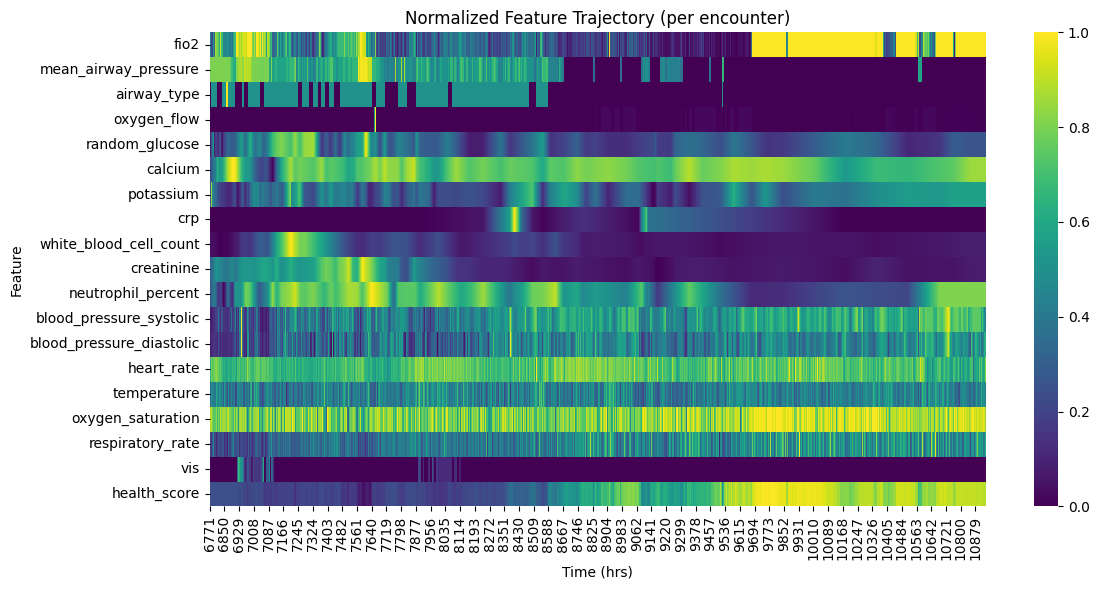

In [10]:
# 1. Min-max normalize each feature
normalized_traj = (example_training_traj - example_training_traj.min()) / (example_training_traj.max() - example_training_traj.min())

# 2. Transpose so features are rows, timepoints are columns
heatmap_data = normalized_traj.T


# 3. Plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap='viridis', cbar=True)
plt.xlabel("Time (hrs)")
plt.ylabel("Feature")
plt.title("Normalized Feature Trajectory (per encounter)")
plt.tight_layout()
plt.show()